<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5641-notebooks/main/_banners/opim5641_banner.svg" width="100%" alt="OPIM 5641 banner"/>

**Dr. Dave Wanik - Operations and Information Management - University of Connecticut**

---

# Studio 6 - Your Final Fund

In Studio 5 you built a fund with Ms. Womack's model and put it on the leaderboard. Tonight you build your **final
fund**: you choose the stocks, you choose the settings, the model sets the shares, and the fund runs until the market
closes on **Wednesday, Dec 2**.

1. **Part 1 - Where I stand.** A quick look at your Studio 5 fund and the class.
2. **Part 2 - The quilt.** The 100 biggest companies in the S&P 500, over three stretches of time.
3. **Part 3 - My picks.** Choose 10 to 25 stocks and say what your strategy is.
4. **Part 4 - Solve.** Ms. Womack's model sets the shares. Change your picks or settings and solve again.
5. **Part 5 - The news (optional).** The news for your fund, a sentiment score, and one PDF to read with Claude.
6. **Part 6 - Name it and send it.** Your fund goes on the leaderboard as **FINAL**.

**The rules for a final fund:** hold **at least 10 stocks**, and put **at most 25%** in any one.

The notebook comes with Dr. Dave's example picks, so it runs from top to bottom as it is: Runtime, Run all. Then make
it yours. You can come back and send a new version as often as you like until Dec 2.

## Setup

Pyomo, the two solvers (ipopt and Bonmin) and yfinance, as in Studio 5. About a minute.

In [1]:
# install Pyomo, the solvers and yfinance in Colab (idaes-pse brings ipopt and Bonmin)
import sys
import os

if 'google.colab' in sys.modules:
    !pip install -q idaes-pse --pre yfinance
    !idaes get-extensions --to ./bin
    os.environ['PATH'] += ':bin'

%matplotlib inline
from pylab import *
import numpy as np
import pandas as pd
import json
import html
import requests
import yfinance as yf
import xml.etree.ElementTree as ET
from pyomo.environ import *
from IPython.display import display
import matplotlib.dates as mdates

import logging
logging.getLogger('pyomo.core').setLevel(logging.ERROR)

# where the setup cell put the solvers
ipopt_path = '/content/bin/ipopt'
bonmin_path = '/content/bin/bonmin'

Getting files...
Done
-----------------------------------------------------------------
IDAES Extensions Build Versions
Solvers:  v3.4.2 20240811 ubuntu2204-x86_64
Library:  v3.4.2 20240811 ubuntu2204-x86_64



## The data

Four things, one step each: the list of companies, tonight's menu, the class's funds, and the prices.

### Step 1 - The companies

`sp500` is a table of the companies in the S&P 500: one row per company, with its name, its sector and its size
(market value, in billions of dollars). We use it all night to look up a ticker's name and sector.

In [2]:
sp500 = pd.read_csv('https://raw.githubusercontent.com/drdave-teaching/OPIM5641-notebooks/main/studio6/data/sp500_2025-12-31.csv').set_index('ticker')
sp500 = sp500[['company', 'sector', 'market_value_billions']]
sp500['sector'] = sp500['sector'].replace('Information Technology', 'Technology')

print("sp500:", sp500.shape[0], "companies,", sp500.shape[1], "columns. The first five rows:")
sp500.head()

sp500: 484 companies, 3 columns. The first five rows:


,company,sector,market_value_billions
ticker,,,
MMM,3M,Industrials,85.3
AOS,A. O. Smith,Industrials,9.4
ABT,Abbott Laboratories,Health Care,218.1
ABBV,AbbVie,Health Care,403.8
ACN,Accenture,Technology,166.4


### Step 2 - Tonight's menu: the 100 biggest

`biggest` is a list of the tickers with the largest market value. It is the menu you pick your final fund from in
Parts 2 and 3. We take the 100 biggest so the pictures fit on a screen. You can change `menu_size` later (try 150) and
run the notebook again.

In [ ]:
menu_size = 100          # how many of the biggest companies are on the menu

biggest = list(sp500.sort_values('market_value_billions', ascending=False).head(menu_size).index)

print("biggest:", len(biggest), "tickers. The ten largest companies:")
sp500.loc[biggest].head(10)

biggest: 100 tickers. The ten largest companies:


,company,sector,market_value_billions
ticker,,,
NVDA,Nvidia,Technology,4540.7
AAPL,Apple Inc.,Technology,4034.5
GOOGL,Alphabet Inc. (Class A),Communication Services,3791.1
MSFT,Microsoft,Technology,3594.8
AMZN,Amazon,Consumer Discretionary,2467.5
META,Meta Platforms,Communication Services,1663.8
AVGO,Broadcom,Technology,1641.0
TSLA,"Tesla, Inc.",Consumer Discretionary,1495.7
BRK-B,Berkshire Hathaway,Financials,1084.4


### Step 3 - The class's Studio 5 funds

One file from the leaderboard has every student's Studio 5 fund. From it we take three things:

* `class_funds`: every student fund, with its leaderboard name and its mix (each stock's share of the fund);
* `crowd_mix`: the **class crowd fund**, which is what you would hold if you put the same dollars in every one of
  those funds;
* `class_start`: **the Nov 5 close**, the day the class funds went live.

In [ ]:
crowd_file = requests.get('https://storage.googleapis.com/opim5641-leaderboard-f26/crowd.json', timeout=30).json()

class_funds = crowd_file['named_funds']                           # a list: one fund per student
crowd_mix = crowd_file['crowd']['weights']                        # the crowd fund: stock -> share
class_start = pd.Timestamp(crowd_file['crowd']['start'])          # Nov 5

print("class_funds:", len(class_funds), "student funds")
for fund in class_funds:
    print("   %-32s %2d stocks" % (fund['name'], len(fund['weights'])))
print()
print("crowd_mix: the class crowd fund holds", len(crowd_mix), "different stocks. Its five biggest:")
for t in list(crowd_mix)[:5]:
    print("   %-6s %4.1f%%" % (t, 100 * crowd_mix[t]))
print()
print("class_start:", class_start.strftime('%A, %B %d'))

class_funds: 14 student funds
   Chong's Funds                    12 stocks
   Damir's fingers crossed          11 stocks
   Kapil Bank Funds                 12 stocks
   Madison's Studio 5               11 stocks
   Matt's Def Not Insider Trading   11 stocks
   Mike's dividends                 11 stocks
   my_pension_fund                  11 stocks
   Preshitha                        12 stocks
   Priyanka Travels                 11 stocks
   Robert's Iron Fist               11 stocks
   SAM                              12 stocks
   Shanmathi Travels                11 stocks
   Tracie Makes Money               12 stocks
   Volatile                         12 stocks

crowd_mix: the class crowd fund holds 79 different stocks. Its five biggest:
   XOM     7.1%
   AAPL    5.9%
   JNJ     5.0%
   CVX     4.2%
   MAR     3.6%

class_start: Thursday, November 05


#### 3a - What is in the class crowd fund?

The crowd fund is every student fund averaged together. A stock gets a big share when **many funds hold it**, or when
**a few funds hold a lot of it**. The table shows its 15 biggest stocks, and how many of the student funds hold each
one.

In [ ]:
# how many of the student funds hold each stock
held_by = {}
for fund in class_funds:
    for t in fund['weights']:
        held_by[t] = held_by.get(t, 0) + 1

# one row per stock in the class crowd fund
rows = []
for t in crowd_mix:
    row = {}
    row['stock'] = t
    row['company'] = sp500.loc[t, 'company']
    row['sector'] = sp500.loc[t, 'sector']
    row['share of the crowd fund (%)'] = round(100 * crowd_mix[t], 1)
    row['student funds that hold it'] = held_by.get(t, 0)
    rows.append(row)
crowd_table = pd.DataFrame(rows).set_index('stock').sort_values('share of the crowd fund (%)', ascending=False)

top = crowd_table.head(15)
print("The class crowd fund holds %d stocks, from %d student funds." % (len(crowd_table), len(class_funds)))
print("Its 15 biggest add up to %.0f%% of the fund. The other %d stocks share the rest." % (
    top['share of the crowd fund (%)'].sum(), len(crowd_table) - 15))
top

The class crowd fund holds 79 stocks, from 14 student funds.
Its 15 biggest add up to 49% of the fund. The other 64 stocks share the rest.


,company,sector,share of the crowd fund (%),student funds that hold it
stock,,,,
XOM,ExxonMobil,Energy,7.1,10
AAPL,Apple Inc.,Technology,5.9,9
JNJ,Johnson & Johnson,Health Care,5.0,8
CVX,Chevron Corporation,Energy,4.2,6
MAR,Marriott International,Consumer Discretionary,3.6,5
RCL,Royal Caribbean Group,Consumer Discretionary,3.6,5
HLT,Hilton Worldwide,Consumer Discretionary,2.9,4
META,Meta Platforms,Communication Services,2.5,4
DAL,Delta Air Lines,Industrials,2.1,3


**By sector.** Add up the shares in each sector. Where did the class put its money?

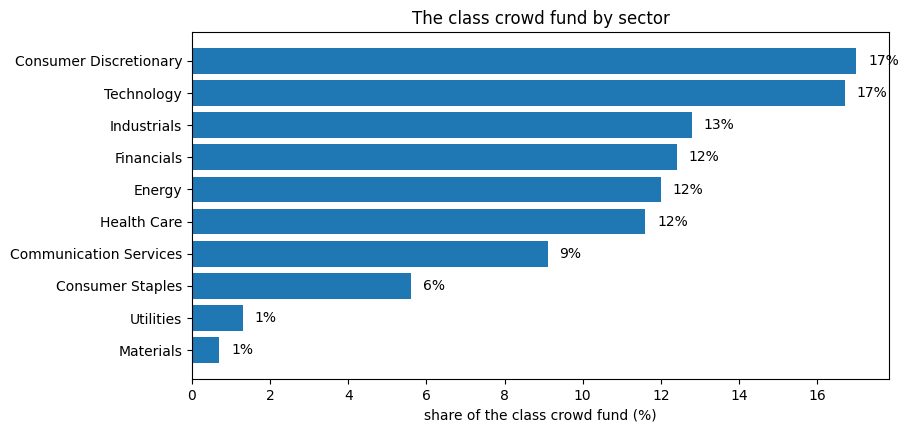

In [ ]:
by_sector = crowd_table.groupby('sector')['share of the crowd fund (%)'].sum().sort_values()

fig, panel = subplots(figsize=(9, 4.5))
panel.barh(by_sector.index, by_sector.values, color='tab:blue')
for k in range(len(by_sector)):
    panel.text(by_sector.values[k] + 0.3, k, "%.0f%%" % by_sector.values[k], va='center')
panel.set_xlabel('share of the class crowd fund (%)')
panel.set_title('The class crowd fund by sector')
show()

### Step 4 - Prices

For every ticker we need **one closing price for every trading day**, from September 2021 to the last close: about
1,300 days. The prices are adjusted for splits and dividends. We need them for three groups of tickers.

#### 4a - Which tickers?

In [ ]:
# SPY (a fund that tracks the S&P 500: our yardstick), the 100 biggest, and every stock the class holds
tickers = ['SPY']
for t in biggest + list(crowd_mix):
    if t not in tickers:
        tickers.append(t)

# how many tickers are on both lists? They are downloaded once.
on_both = 0
for t in crowd_mix:
    if t in biggest:
        on_both += 1

print("The 100 biggest:               %4d tickers (for the quilt and my picks)" % len(biggest))
print("The class's stocks:          + %4d tickers (for the class picture)" % len(crowd_mix))
print("On both lists, counted once: - %4d tickers" % on_both)
print("SPY, our yardstick:          + %4d ticker" % 1)
print("                               ----")
print("To download:                   %4d tickers, one closing price a day since September 2021" % len(tickers))

The 100 biggest:                100 tickers (for the quilt and my picks)
The class's stocks:          +   79 tickers (for the class picture)
On both lists, counted once: -   46 tickers
SPY, our yardstick:          +    1 ticker
                               ----
To download:                    134 tickers, one closing price a day since September 2021


#### 4b - Ask Yahoo Finance

In [ ]:
try:
    prices = yf.download(tickers, start='2021-09-01', interval='1d', auto_adjust=True, progress=False)['Close']
except Exception as problem:
    prices = pd.DataFrame()

if len(prices) > 0:
    print("Yahoo answered: %d days of prices for %d tickers, from %s to %s." % (
        prices.shape[0], prices.shape[1], prices.index[0].strftime('%b %d, %Y'), prices.index[-1].strftime('%b %d, %Y')))
else:
    print("Yahoo did not answer. The next step uses the backup.")

Yahoo answered: 1310 days of prices for 134 tickers, from Sep 01, 2021 to Nov 18, 2026.


#### 4c - The backup

Yahoo Finance is free and sometimes refuses Colab, usually when a whole class asks at once. So the course keeps a
**backup file**: `daily_prices.csv`, in the same GitHub folder as this notebook. It has the same kind of prices (daily
closes, adjusted) for about 485 tickers (S&P 500 companies and SPY), from September 2021. Dr. Dave refreshes it before class, and
the cell says the last day it has.

If Yahoo did not answer, the notebook uses the backup and **everything below works the same**. The only difference is
that the backup's last day may be a day behind. If the backup is used, the cell shows its last three days.

In [ ]:
class_copy = pd.read_csv('https://raw.githubusercontent.com/drdave-teaching/OPIM5641-notebooks/main/studio6/data/daily_prices.csv', index_col=0, parse_dates=True)
print("The backup has %d tickers, from %s." % (class_copy.shape[1], class_copy.index[0].strftime('%b %d, %Y')))
print("It was last updated through the close of %s." % class_copy.index[-1].strftime('%A, %b %d, %Y'))
print()

used_backup = False

# Yahoo gave us nothing: use the backup for everything
if 'SPY' not in prices.columns or prices['SPY'].notna().sum() < 200:
    prices = class_copy.copy()
    used_backup = True

# Yahoo skipped a ticker: take that one from the backup
for t in tickers:
    if t not in prices.columns or prices[t].notna().sum() == 0:
        prices[t] = class_copy[t].reindex(prices.index)
        used_backup = True

if used_backup:
    print("Yahoo did not give us everything, so prices come from the backup. Carry on as usual.")
    print("The backup's last three days, for five of the biggest companies:")
    display(class_copy[biggest[:5]].tail(3).round(2))
else:
    print("Yahoo gave us every ticker, so the backup was not needed.")

The backup has 485 tickers, from Sep 01, 2021.
It was last updated through the close of Tuesday, Nov 17, 2026.

Yahoo gave us every ticker, so the backup was not needed.


#### 4d - Tidy up

Put the days in order, fill a missing day with the day before, and drop today if the market has not closed yet.

In [ ]:
prices = prices.sort_index().ffill().copy()

# today's price is not a closing price until the market closes (4 PM Eastern; we wait until 4:30)
now = pd.Timestamp.now(tz='America/New_York')
if now.hour * 60 + now.minute < 16 * 60 + 30:
    prices = prices[prices.index < pd.Timestamp(now.date())]
last_close = prices.index[-1]

print("prices:", prices.shape[0], "days,", prices.shape[1], "tickers, through the close of", last_close.strftime('%a %b %d, %Y'))
print("The last three days for five of the biggest companies:")
prices[biggest[:5]].tail(3).round(2)

prices: 1310 days, 134 tickers, through the close of Wed Nov 18, 2026
The last three days for five of the biggest companies:


Ticker,NVDA,AAPL,GOOGL,MSFT,AMZN
Date,,,,,
2026-11-16,156.14,352.78,283.72,517.99,257.75
2026-11-17,155.46,351.91,280.20,506.24,257.89
2026-11-18,150.96,352.45,282.44,508.29,267.74


### Step 5 - The starting line: \$10,000 at the Nov 5 close

Tonight, every look back at the class uses **the same starting line**: \$10,000 put in at the **Nov 5 close**, then
left alone. That goes for every one of the student funds, for the class crowd fund and for the S&P 500, so they can be
compared fairly. (A few funds really started a day or two later. Using one day for everyone keeps it simple.)

`hold` does that for any mix of stocks. It is the same idea as Studio 5, Part 4c.

In [ ]:
def hold(mix, day):
    # $10,000 split by `mix` (stock -> share) at the close of `day`, then held: its value at every close after that
    window = prices.loc[day:]
    line = 0
    for t in mix:
        line = line + 10000 * mix[t] * window[t] / window[t].iloc[0]
    return line


spy_line = hold({'SPY': 1.0}, class_start)          # the S&P 500 since Nov 5
crowd_line = hold(crowd_mix, class_start)           # the class crowd fund since Nov 5

print("$10,000 put in at the %s close, as of the %s close:" % (class_start.strftime('%b %d'), last_close.strftime('%b %d')))
print("   the S&P 500:                         $%.0f" % spy_line.iloc[-1])
print("   the class crowd fund (%d funds):      $%.0f" % (len(class_funds), crowd_line.iloc[-1]))

$10,000 put in at the Nov 05 close, as of the Nov 18 close:
   the S&P 500:                         $9962
   the class crowd fund (14 funds):      $9996


#### 5a - Every fund since Nov 5

The same \$10,000 at the Nov 5 close, for every student fund, the class crowd fund and the S&P 500. Blue is up and red
is down.

In [ ]:
rows = []
ahead_of_crowd = 0
ahead_of_spy = 0

# every student fund
for fund in class_funds:
    line = hold(fund['weights'], class_start)
    row = {}
    row['fund'] = fund['name']
    row['stocks'] = len(fund['weights'])
    row['$10,000 is now'] = line.iloc[-1]
    row['return since Nov 5 (%)'] = 100 * (line.iloc[-1] / 10000 - 1)
    rows.append(row)
    if line.iloc[-1] > crowd_line.iloc[-1]:
        ahead_of_crowd += 1
    if line.iloc[-1] > spy_line.iloc[-1]:
        ahead_of_spy += 1

# the class crowd fund and the S&P 500, in capital letters so they are easy to find
rows.append({'fund': 'THE CLASS CROWD FUND', 'stocks': len(crowd_mix), '$10,000 is now': crowd_line.iloc[-1],
             'return since Nov 5 (%)': 100 * (crowd_line.iloc[-1] / 10000 - 1)})
rows.append({'fund': 'THE S&P 500', 'stocks': 500, '$10,000 is now': spy_line.iloc[-1],
             'return since Nov 5 (%)': 100 * (spy_line.iloc[-1] / 10000 - 1)})

scoreboard = pd.DataFrame(rows).set_index('fund').sort_values('return since Nov 5 (%)', ascending=False)

print("%d of the %d student funds are ahead of the S&P 500." % (ahead_of_spy, len(class_funds)))
print("%d of the %d student funds are ahead of the class crowd fund." % (ahead_of_crowd, len(class_funds)))

# the same color scale on both sides of zero
edge = scoreboard['return since Nov 5 (%)'].abs().max()
scoreboard.style.background_gradient(cmap='RdYlBu', subset=['return since Nov 5 (%)'], vmin=-edge, vmax=edge).format(
    {'$10,000 is now': '${:,.0f}', 'return since Nov 5 (%)': '{:+.1f}'})

7 of the 14 student funds are ahead of the S&P 500.
4 of the 14 student funds are ahead of the class crowd fund.


,stocks,"$10,000 is now",return since Nov 5 (%)
fund,,,
Preshitha,12,"$10,927",+9.3
Robert's Iron Fist,11,"$10,091",+0.9
Madison's Studio 5,11,"$10,047",+0.5
Matt's Def Not Insider Trading,11,"$10,037",+0.4
THE CLASS CROWD FUND,79,"$9,996",-0.0
Volatile,12,"$9,995",-0.0
Chong's Funds,12,"$9,995",-0.0
my_pension_fund,11,"$9,987",-0.1
THE S&P 500,500,"$9,962",-0.4


# Part 1 - Where I stand

A look back before you build something new: what happened to the fund you sent in Studio 5?

### 🎯 My Studio 5 fund

Type the **name of your Studio 5 fund**, as it appears on the leaderboard. The next cell prints every fund's name, so
you can copy yours. The name below is Dr. Dave's example fund.

No Studio 5 fund? Make it `''` and go on to **The class**.

In [ ]:
my_fund_name = "Kapil Bank Funds"       # my Studio 5 fund's name on the leaderboard

In [ ]:
# the leaderboard keeps a list of every Studio 5 fund and where its record is
fund_list = requests.get('https://storage.googleapis.com/opim5641-leaderboard-f26/fund_records.json', timeout=30).json()['funds']

print("The Studio 5 funds on the leaderboard:")
for fund in fund_list:
    print("   ", fund['name'])

# find mine (capital letters and spaces at the ends do not matter)
record_link = ''
for fund in fund_list:
    if fund['name'].strip().lower() == my_fund_name.strip().lower():
        record_link = fund['record']

print()
if my_fund_name.strip() == '':
    print("No Studio 5 fund: go on to The class.")
elif record_link == '':
    raise ValueError("I cannot find a fund called '%s'. Copy your fund's name from the list above." % my_fund_name)
else:
    # my record: every version of my fund, and its value at every close
    my_record = requests.get(record_link, timeout=30).json()
    print("Loaded:", my_record['nickname'], "|", my_record['theme'])

The Studio 5 funds on the leaderboard:
    Chong's Funds
    Damir's fingers crossed
    Dr. Dave: AI + Energy (50/200 Momentum)
    Dr. Dave: AI + Energy (Womack)
    Dr. Dave: Dartboard
    Dr. Dave: Steady Dividends
    Kapil Bank Funds
    Madison's Studio 5
    Matt's Def Not Insider Trading
    Mike's dividends
    my_pension_fund
    Preshitha
    Priyanka Travels
    Robert's Iron Fist
    SAM
    Shanmathi Travels
    Tracie Makes Money
    Volatile

Loaded: Kapil Bank Funds | Banks And Payments


**The race so far.** Your fund (blue), its **no-rules twin** (gray: the plain Ms. Womack model on the same stocks,
with no business rules) and the S&P 500 (black), each starting with \$10,000 on your fund's first day.

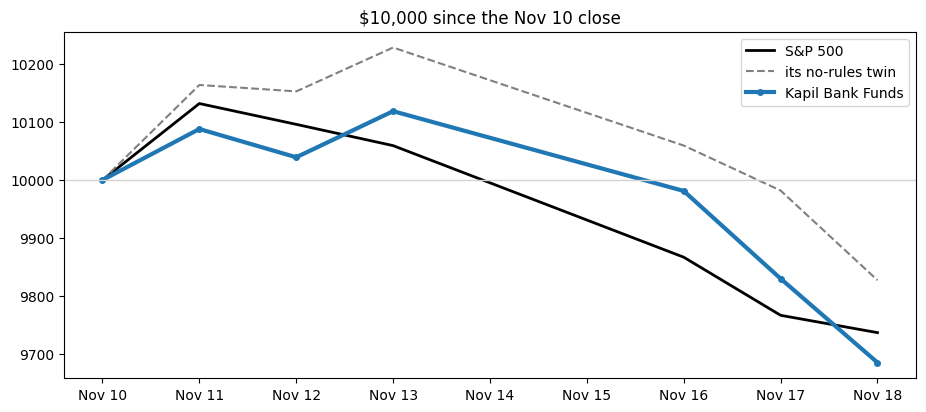

$10,000 since the Nov 10 close:
   Kapil Bank Funds:            $9686
   its no-rules twin:           $9827
   the S&P 500:                 $9737


In [ ]:
if record_link == '':
    print("No Studio 5 fund loaded. Go on to The class.")
else:
    # my fund and its no-rules twin at every close, straight from the leaderboard
    days = pd.to_datetime(my_record['values']['dates'])
    my_line = pd.Series(my_record['values']['with_rules'], index=days)
    twin_line = pd.Series(my_record['values']['no_rules'], index=days)

    # the S&P 500 over the same days
    market_line = hold({'SPY': 1.0}, days[0])

    fig, panel = subplots(figsize=(11, 4.5))
    panel.plot(market_line.index, market_line.values, color='black', linewidth=2, label='S&P 500')
    panel.plot(twin_line.index, twin_line.values, color='gray', linewidth=1.5, linestyle='--', label='its no-rules twin')
    panel.plot(my_line.index, my_line.values, color='tab:blue', linewidth=3, marker='o', markersize=4, label=my_record['nickname'])
    panel.axhline(10000, color='lightgray', linewidth=1)
    panel.set_title('$10,000 since the %s close' % days[0].strftime('%b %d'))
    panel.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    panel.legend()
    show()

    print("$10,000 since the %s close:" % days[0].strftime('%b %d'))
    print("   %-28s $%.0f" % (my_record['nickname'] + ':', my_line.iloc[-1]))
    print("   %-28s $%.0f" % ('its no-rules twin:', twin_line.iloc[-1]))
    print("   %-28s $%.0f" % ('the S&P 500:', market_line.iloc[-1]))

**What drove it.** One row for each stock you hold now: the company, the share of your fund you put in it, its
return since you bought it, and the dollars that added or took away.

$$\text{dollars added} = \text{dollars I put in} \times \text{its return}$$

In [ ]:
if record_link == '':
    print("No Studio 5 fund loaded. Go on to The class.")
else:
    # the newest version of my fund that has started counting: its mix, and the day I bought it
    for entry in my_record['entries']:
        if entry['counts_from'] is not None:
            newest = entry
    old_mix = newest['portfolios']['with_rules']
    bought_day = pd.Timestamp(newest['counts_from'])
    money_then = float(my_line.loc[bought_day])          # what my fund was worth that day

    # stocks I hold that are not in the price table yet: download them and add them in one step
    extra = []
    for t in old_mix:
        if t not in prices.columns:
            extra.append(t)
    if len(extra) > 0:
        more = yf.download(extra, start='2021-09-01', interval='1d', auto_adjust=True, progress=False)['Close']
        if len(extra) == 1:
            more = more.squeeze().to_frame(extra[0])          # one ticker comes back as a single column
        prices = pd.concat([prices, more.reindex(prices.index).ffill()], axis=1)

    rows = []
    for t in old_mix:
        stock_return = prices.loc[last_close, t] / prices.loc[bought_day, t] - 1
        row = {}
        row['stock'] = t
        if t in sp500.index:
            row['company'] = sp500.loc[t, 'company']
        else:
            row['company'] = t
        row['share I bought (%)'] = round(100 * old_mix[t], 1)
        row['return since %s (%%)' % bought_day.strftime('%b %d')] = round(100 * stock_return, 1)
        row['dollars added'] = round(money_then * old_mix[t] * stock_return)
        rows.append(row)
    drove = pd.DataFrame(rows).set_index('stock').sort_values('dollars added', ascending=False)

    best = drove.index[0]
    worst = drove.index[-1]
    print("I bought these stocks at the %s close, when my fund was worth $%.0f." % (bought_day.strftime('%b %d'), money_then))
    print("Helped the most: %s (%s), %.1f%% of my fund, %+.0f dollars." % (drove.loc[best, 'company'], best, drove.loc[best, 'share I bought (%)'], drove.loc[best, 'dollars added']))
    print("Hurt the most:   %s (%s), %.1f%% of my fund, %+.0f dollars." % (drove.loc[worst, 'company'], worst, drove.loc[worst, 'share I bought (%)'], drove.loc[worst, 'dollars added']))
    display(drove)

I bought these stocks at the Nov 11 close, when my fund was worth $10088.
Helped the most: Charles Schwab Corporation (SCHW), 5.5% of my fund, +1 dollars.
Hurt the most:   Goldman Sachs (GS), 10.0% of my fund, -58 dollars.


,company,share I bought (%),return since Nov 11 (%),dollars added
stock,,,,
SCHW,Charles Schwab Corporation,5.5,0.1,1
MA,Mastercard,2.5,-2.6,-7
AAPL,Apple Inc.,10.0,-0.8,-8
V,Visa Inc.,10.0,-2.4,-24
AXP,American Express,10.0,-2.4,-24
UNH,UnitedHealth Group,2.0,-13.2,-27
CVX,Chevron Corporation,10.0,-3.5,-35
MS,Morgan Stanley,10.0,-5.0,-50
C,Citigroup,10.0,-5.5,-56


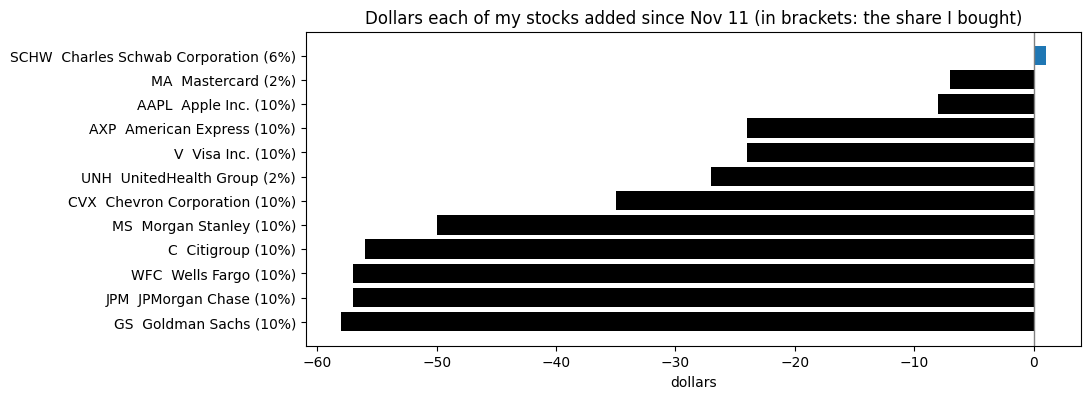

In [ ]:
if record_link == '':
    print("No Studio 5 fund loaded. Go on to The class.")
else:
    # the same dollars as bars: blue added money, black took it away
    bars = drove['dollars added'].sort_values()
    labels = []
    colors = []
    for t in bars.index:
        labels.append('%s  %s (%.0f%%)' % (t, drove.loc[t, 'company'], drove.loc[t, 'share I bought (%)']))
        if bars[t] >= 0:
            colors.append('tab:blue')
        else:
            colors.append('black')

    fig, panel = subplots(figsize=(10, max(3.5, 0.34 * len(bars))))
    panel.barh(labels, bars.values, color=colors)
    panel.axvline(0, color='gray', linewidth=1)
    panel.set_title('Dollars each of my stocks added since %s (in brackets: the share I bought)' % bought_day.strftime('%b %d'))
    panel.set_xlabel('dollars')
    show()

### The class quilt

Investors call a picture like this a **quilt**: a grid of colored squares that shows at a glance what went up and what
went down. The well-known ones show sectors or kinds of investments year by year
([the sector quilt](https://novelinvestor.com/sector-performance/),
[the Callan periodic table](https://www.callan.com/periodic-table/)). This one is ours.

Every student fund is a row, biggest holding on the left. Each square is a stock, colored by its return **since the
Nov 5 close**: **blue went up, red went down**, and yellow hardly moved. The number after each fund's name is what
\$10,000 in that fund has done since Nov 5.

The page **Who holds what** on the leaderboard has the same funds with every share:
https://storage.googleapis.com/opim5641-leaderboard-f26/holdings.html

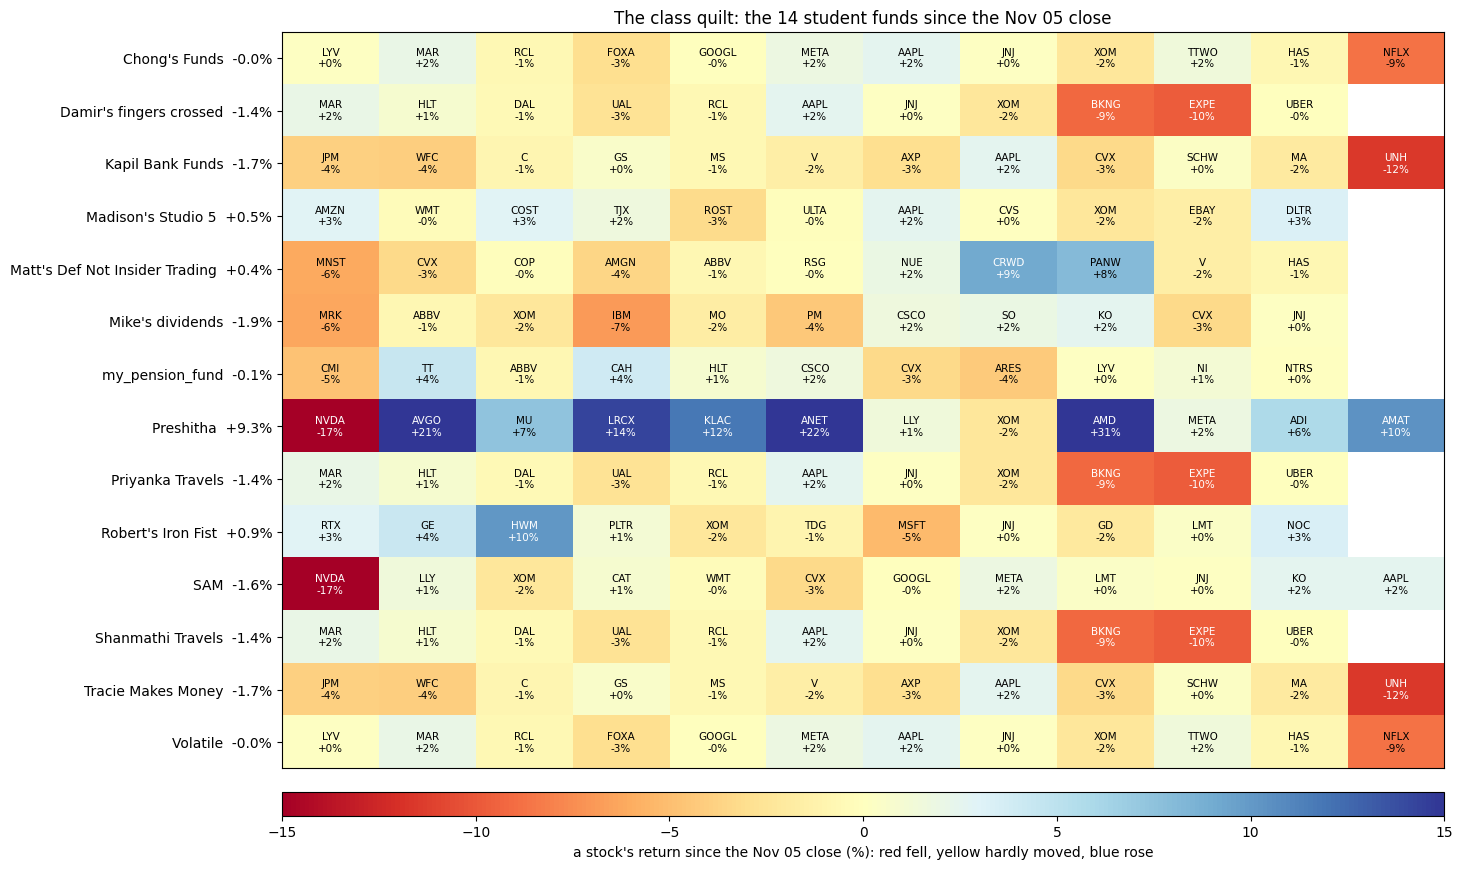

Since the Nov 05 close:
   the class crowd fund (the same dollars in each of the 14 funds): -0.04%
   the S&P 500:                                                    -0.38%


In [ ]:
since_start = 100 * (prices.loc[last_close] / prices.loc[class_start] - 1)        # every stock's return since Nov 5

# one row per fund, one square per holding
widest = 0
for fund in class_funds:
    widest = max(widest, len(fund['weights']))

grid = np.full((len(class_funds), widest), np.nan)
fund_names = []
fig, panel = subplots(figsize=(1.0 * widest + 3, 0.6 * len(class_funds) + 2))
for i in range(len(class_funds)):
    mix = class_funds[i]['weights']
    fund_returns = 100 * (hold(mix, class_start).iloc[-1] / 10000 - 1)
    fund_names.append('%s  %+.1f%%' % (class_funds[i]['name'], fund_returns))
    k = 0
    for t in sorted(mix, key=mix.get, reverse=True):
        grid[i, k] = since_start[t]
        ink = 'black'
        if abs(since_start[t]) > 9:          # a very dark square: white letters are easier to read
            ink = 'white'
        panel.text(k, i, '%s\n%+.0f%%' % (t, since_start[t]), ha='center', va='center', fontsize=7.5, color=ink)
        k += 1
squares = panel.imshow(grid, cmap='RdYlBu', vmin=-15, vmax=15, aspect='auto')
panel.set_yticks(np.arange(len(class_funds)))
panel.set_yticklabels(fund_names)
panel.set_xticks([])
panel.set_title("The class quilt: the %d student funds since the %s close" % (len(class_funds), class_start.strftime('%b %d')))

# the legend, right below the picture
legend = fig.colorbar(squares, ax=panel, orientation='horizontal', pad=0.03, fraction=0.05, aspect=50)
legend.set_label("a stock's return since the %s close (%%): red fell, yellow hardly moved, blue rose" % class_start.strftime('%b %d'))
show()

crowd_return = 100 * (crowd_line.iloc[-1] / 10000 - 1)
spy_return = 100 * (spy_line.iloc[-1] / 10000 - 1)
print("Since the %s close:" % class_start.strftime('%b %d'))
print("   the class crowd fund (the same dollars in each of the %d funds): %+.2f%%" % (len(class_funds), crowd_return))
print("   the S&P 500:                                                    %+.2f%%" % spy_return)

**The class's biggest winners and losers.** Of all the stocks the class holds, the five that rose the most and the
five that fell the most since Nov 5, and which funds hold them.

In [ ]:
# every stock the class holds, and the names of the funds that hold it
holders = {}
for fund in class_funds:
    for t in fund['weights']:
        if t not in holders:
            holders[t] = []
        holders[t].append(fund['name'])

rows = []
for t in holders:
    row = {}
    row['stock'] = t
    if t in sp500.index:
        row['company'] = sp500.loc[t, 'company']
    else:
        row['company'] = t
    row['return since Nov 5 (%)'] = round(since_start[t], 1)
    row['funds holding it'] = len(holders[t])
    row['held by'] = ', '.join(holders[t])
    rows.append(row)
class_stocks = pd.DataFrame(rows).set_index('stock').sort_values('return since Nov 5 (%)', ascending=False)

print("The class holds", len(class_stocks), "different stocks. The five biggest winners:")
for t in class_stocks.index[:5]:
    print("   %-28s %+6.1f%%   held by %s" % (class_stocks.loc[t, 'company'] + ' (' + t + ')', class_stocks.loc[t, 'return since Nov 5 (%)'], class_stocks.loc[t, 'held by']))
print()
print("The five biggest losers:")
for t in class_stocks.index[-5:][::-1]:
    print("   %-28s %+6.1f%%   held by %s" % (class_stocks.loc[t, 'company'] + ' (' + t + ')', class_stocks.loc[t, 'return since Nov 5 (%)'], class_stocks.loc[t, 'held by']))

The class holds 79 different stocks. The five biggest winners:
   Advanced Micro Devices (AMD)  +31.1%   held by Preshitha
   Arista Networks (ANET)        +21.9%   held by Preshitha
   Broadcom (AVGO)               +21.4%   held by Preshitha
   Lam Research (LRCX)           +14.3%   held by Preshitha
   KLA Corporation (KLAC)        +11.8%   held by Preshitha

The five biggest losers:
   Nvidia (NVDA)                 -16.9%   held by Preshitha, SAM
   UnitedHealth Group (UNH)      -11.6%   held by Kapil Bank Funds, Tracie Makes Money
   Expedia Group (EXPE)           -9.8%   held by Damir's fingers crossed, Priyanka Travels, Shanmathi Travels
   Booking Holdings (BKNG)        -9.2%   held by Damir's fingers crossed, Priyanka Travels, Shanmathi Travels
   Netflix (NFLX)                 -8.8%   held by Chong's Funds, Volatile


# Part 2 - The quilt

Now the wider market: the biggest companies in the S&P 500, as a quilt. One row for each sector, the biggest company
on the left. Every company sits in the **same square in all three pictures**, so you can follow one stock across three
stretches of time:

* **since Nov 5** (the last two weeks),
* **2026 so far**,
* **the last 3 years**.

**Blue went up, red went down**, and yellow hardly moved. The number in each square is the percent return.

### The numbers behind the quilt

`menu` has one row per company: its return over each of the three stretches, and the two things Ms. Womack's model
looks at:

* **average monthly return:** the average of a stock's monthly returns, here over the last 5 years and over the last 1 year;
* **monthly swing:** the standard deviation of its monthly returns, also over 5 years and over 1 year. It says how
  far a typical month lands from the average. A stock with an average monthly return of 2% and a swing of 8% often has months near -6% or +10%.
  A small swing is a calm stock.

In [ ]:
# the three stretches of time
year_start = prices.loc['2026-01-01':].index[0]
three_years_ago = prices.loc[last_close - pd.DateOffset(years=3):].index[0]

# month-end prices and monthly returns (complete months only: this month is not over yet)
month_end = prices.groupby(prices.index.to_period('M')).last()
month_end = month_end[month_end.index < last_close.to_period('M')]
monthly = month_end.pct_change(fill_method=None).iloc[1:]

menu = sp500.loc[biggest, ['company', 'sector']].copy()
menu['since Nov 5 (%)'] = 0.0
menu['2026 so far (%)'] = 0.0
menu['last 3 years (%)'] = 0.0
menu['average monthly return, 5 years (%)'] = 0.0
menu['average monthly return, 1 year (%)'] = 0.0
menu['monthly swing, 5 years (%)'] = 0.0
menu['monthly swing, 1 year (%)'] = 0.0
for t in biggest:
    menu.loc[t, 'since Nov 5 (%)'] = round(100 * (prices.loc[last_close, t] / prices.loc[class_start, t] - 1), 1)
    menu.loc[t, '2026 so far (%)'] = round(100 * (prices.loc[last_close, t] / prices.loc[year_start, t] - 1), 1)
    menu.loc[t, 'last 3 years (%)'] = round(100 * (prices.loc[last_close, t] / prices.loc[three_years_ago, t] - 1), 1)
    menu.loc[t, 'average monthly return, 5 years (%)'] = round(100 * monthly[t].tail(60).mean(), 2)
    menu.loc[t, 'average monthly return, 1 year (%)'] = round(100 * monthly[t].tail(12).mean(), 2)
    menu.loc[t, 'monthly swing, 5 years (%)'] = round(100 * monthly[t].tail(60).std(), 2)
    menu.loc[t, 'monthly swing, 1 year (%)'] = round(100 * monthly[t].tail(12).std(), 2)

print("Of the", len(menu), "companies on the menu, how many are up?")
print("   since Nov 5:    %d" % (menu['since Nov 5 (%)'] > 0).sum())
print("   2026 so far:    %d" % (menu['2026 so far (%)'] > 0).sum())
print("   last 3 years:   %d" % (menu['last 3 years (%)'] > 0).sum())
print()
print("menu:", menu.shape[0], "rows. The first five:")
menu.head()

Of the 100 companies on the menu, how many are up?
   since Nov 5:    45
   2026 so far:    60
   last 3 years:   90

menu: 100 rows. The first five:


,company,sector,since Nov 5 (%),2026 so far (%),last 3 years (%),"average monthly return, 5 years (%)","average monthly return, 1 year (%)","monthly swing, 5 years (%)","monthly swing, 1 year (%)"
ticker,,,,,,,,,
NVDA,Nvidia,Technology,-16.9,-19.9,200.4,4.53,0.42,14.39,8.18
AAPL,Apple Inc.,Technology,2.5,30.5,86.5,1.69,2.24,7.12,6.15
GOOGL,Alphabet Inc. (Class A),Communication Services,-0.0,-10.2,109.3,1.50,0.72,9.34,13.24
MSFT,Microsoft,Technology,-5.2,8.2,37.5,1.10,0.72,7.59,11.50
AMZN,Amazon,Consumer Discretionary,2.9,18.2,83.2,1.06,0.37,9.82,10.94


### The quilt, three times

In each picture, a **black outline** marks the **ten companies with the best return over that stretch of time**. Each
picture has its own ten: the best ten since Nov 5 are not the best ten of the last three years.

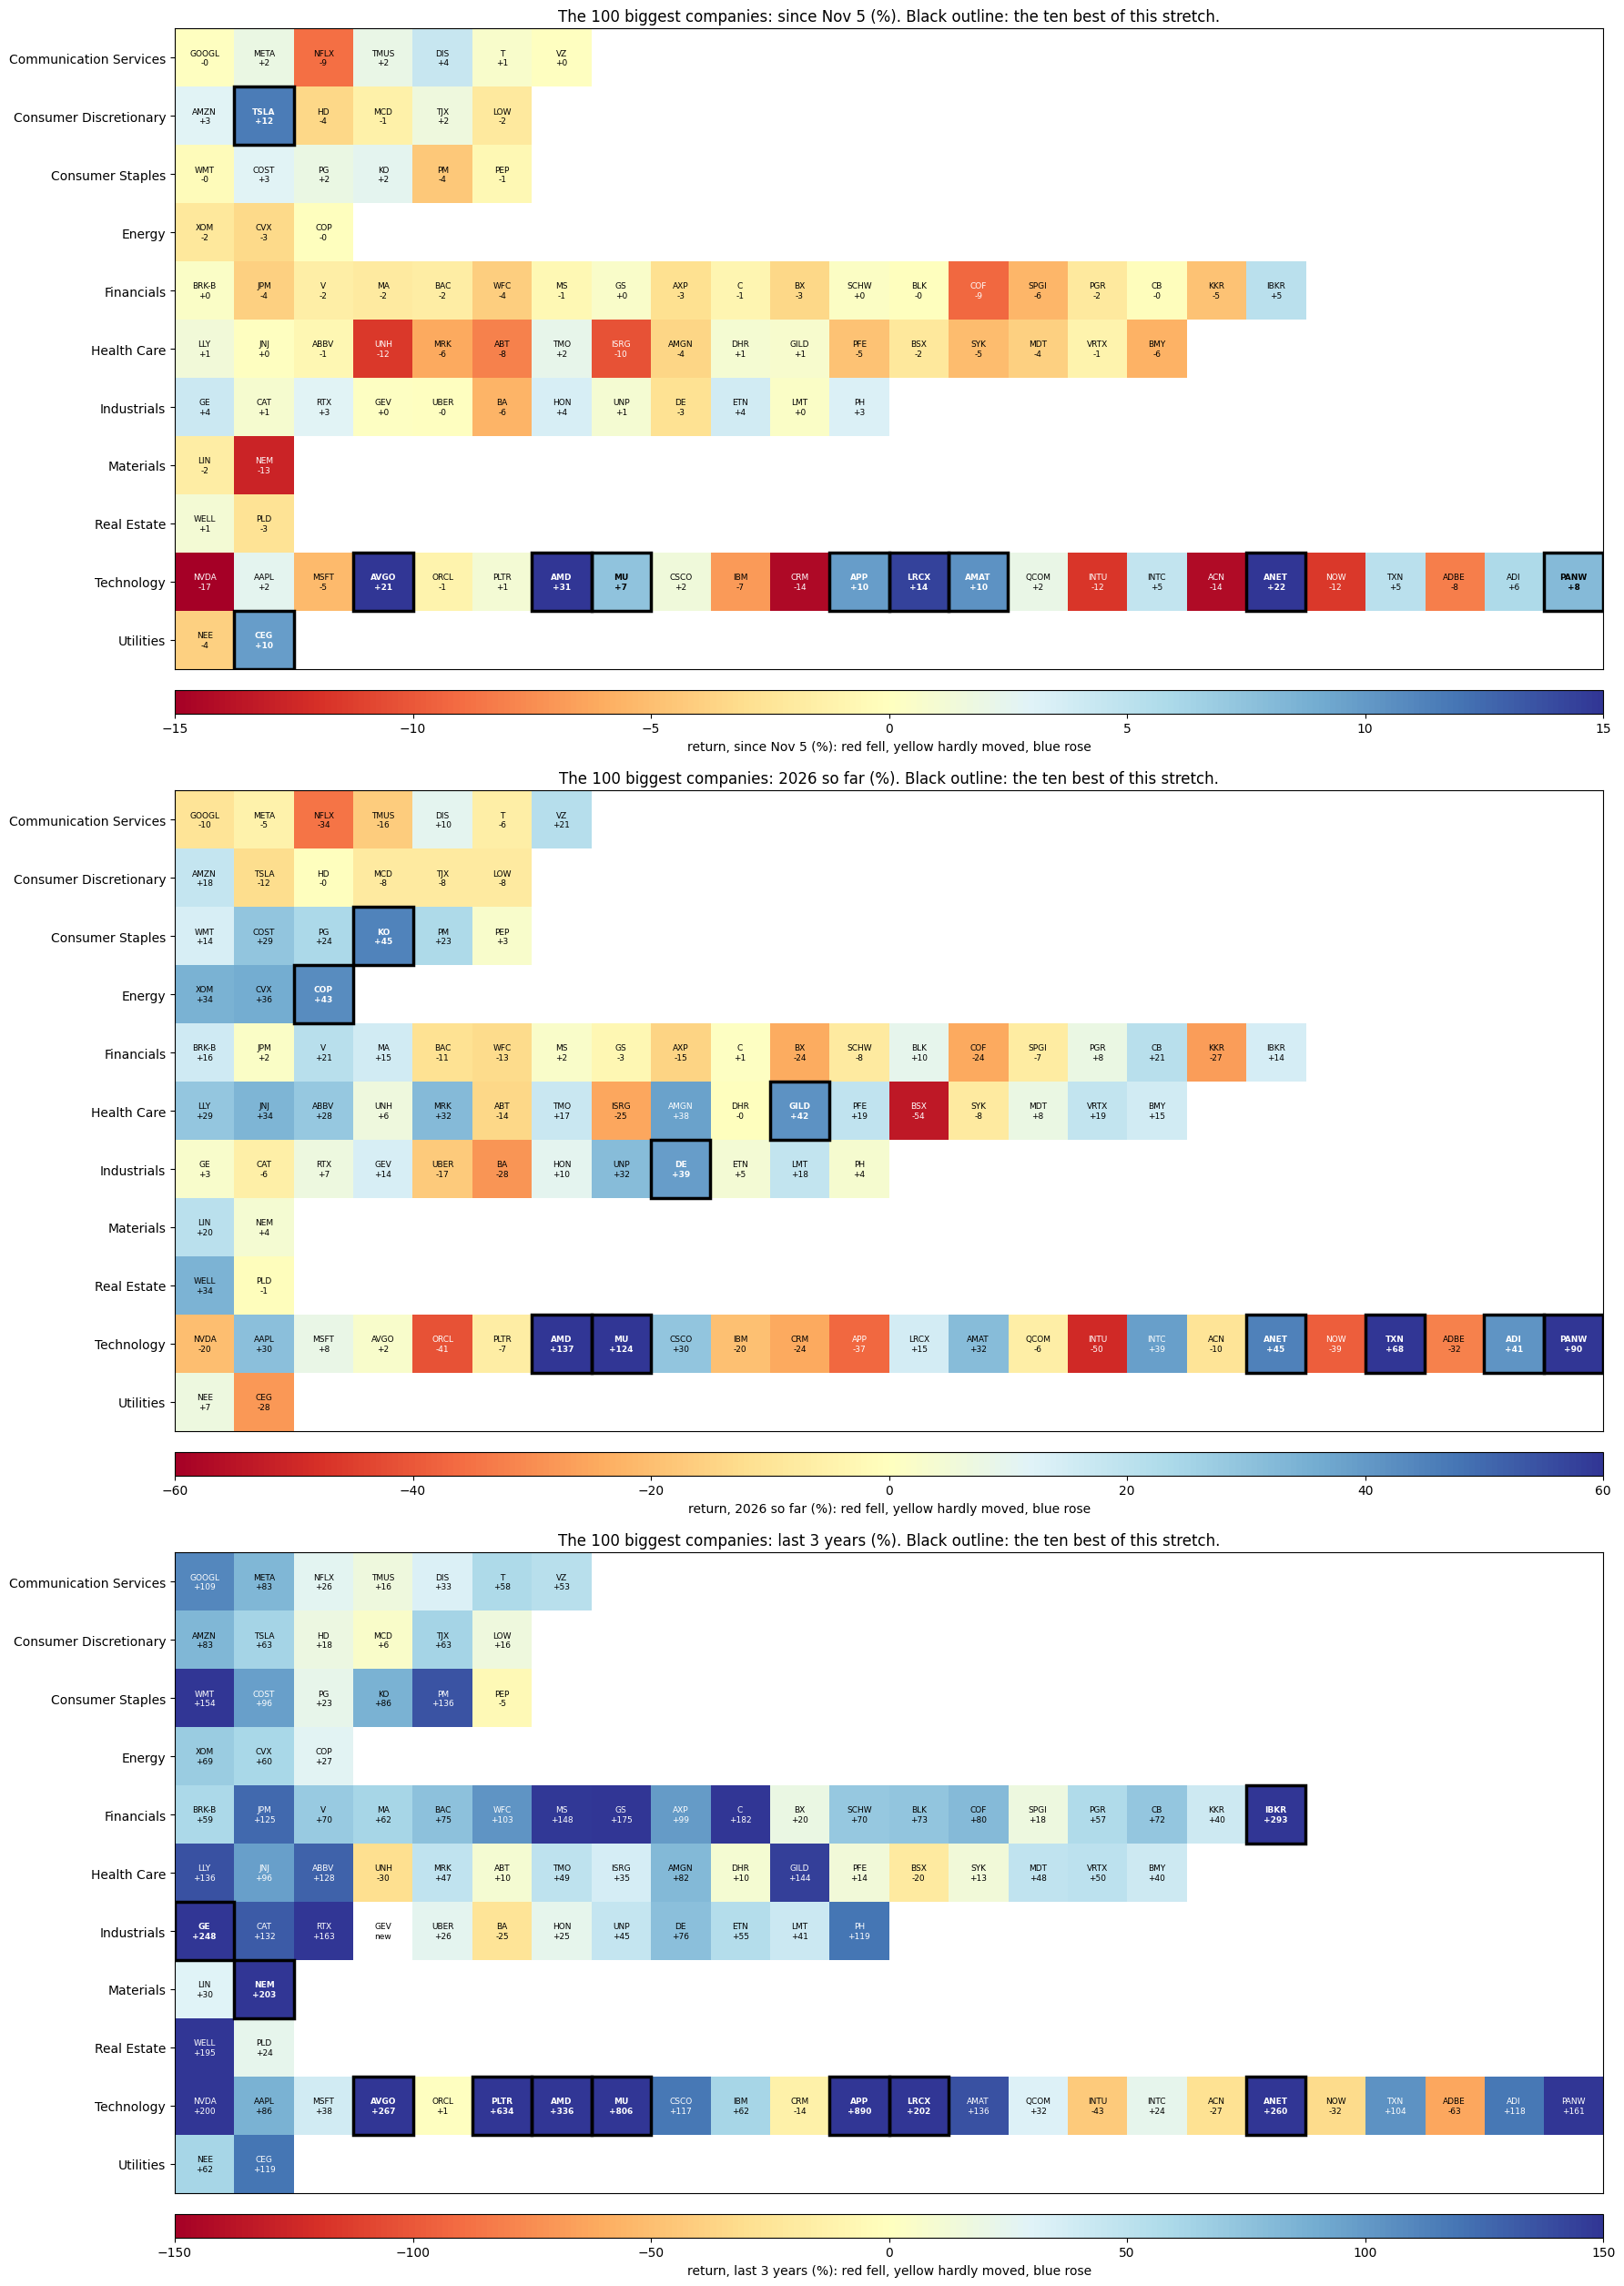

In [ ]:
# the same layout three times: one row per sector, companies from biggest to smallest
sectors = sorted(menu['sector'].unique())
widest = menu['sector'].value_counts().max()

# each picture has its own color scale: (column, the return that gets the darkest color)
pictures = [('since Nov 5 (%)', 15), ('2026 so far (%)', 60), ('last 3 years (%)', 150)]

fig, panels = subplots(3, 1, figsize=(0.62 * widest + 3, 3 * (0.62 * len(sectors) + 1.6)))
for p in range(3):
    column = pictures[p][0]
    darkest = pictures[p][1]
    best_ten = list(menu.sort_values(column, ascending=False).head(10).index)      # the ten best of this stretch
    grid = np.full((len(sectors), widest), np.nan)
    for i in range(len(sectors)):
        row = menu[menu['sector'] == sectors[i]]          # already in order of size
        k = 0
        for t in row.index:
            number = row.loc[t, column]
            grid[i, k] = number

            # the words in the square
            if number == number:
                label = '%s\n%+.0f' % (t, number)
            else:
                label = '%s\nnew' % t          # a company that has not traded for the whole stretch

            # white letters on the darkest squares, so the ticker is always readable
            ink = 'black'
            if number == number and abs(number) > 0.6 * darkest:
                ink = 'white'

            # one of the ten best: a black outline and bold letters
            weight = 'normal'
            if t in best_ten:
                panels[p].add_patch(Rectangle((k - 0.5, i - 0.5), 1, 1, fill=False, edgecolor='black', linewidth=2.5))
                weight = 'bold'
            panels[p].text(k, i, label, ha='center', va='center', fontsize=6.5, color=ink, fontweight=weight)
            k += 1
    squares = panels[p].imshow(grid, cmap='RdYlBu', vmin=-darkest, vmax=darkest, aspect='auto')
    legend = fig.colorbar(squares, ax=panels[p], orientation='horizontal', pad=0.03, fraction=0.04, aspect=60)
    legend.set_label('return, %s: red fell, yellow hardly moved, blue rose' % column)
    panels[p].set_yticks(np.arange(len(sectors)))
    panels[p].set_yticklabels(sectors)
    panels[p].set_xticks([])
    panels[p].set_title('The %d biggest companies: %s. Black outline: the ten best of this stretch.' % (len(menu), column))
tight_layout()
show()

**Read the quilt.**

* The black outlines are the ten best of each stretch. Which sector has most of them? Which companies are outlined
  in more than one picture?
* Find a square that is blue over three years and red since Nov 5.
* Find NVIDIA (`NVDA`, the first square in the Technology row) in all three pictures.

### By sector

The same numbers, one sector at a time. The **bar** is the average company in the sector. The **gray line** runs from
the sector's worst company to its best, with their tickers at the ends. A long gray line means the sector had big
winners and big losers at the same time.

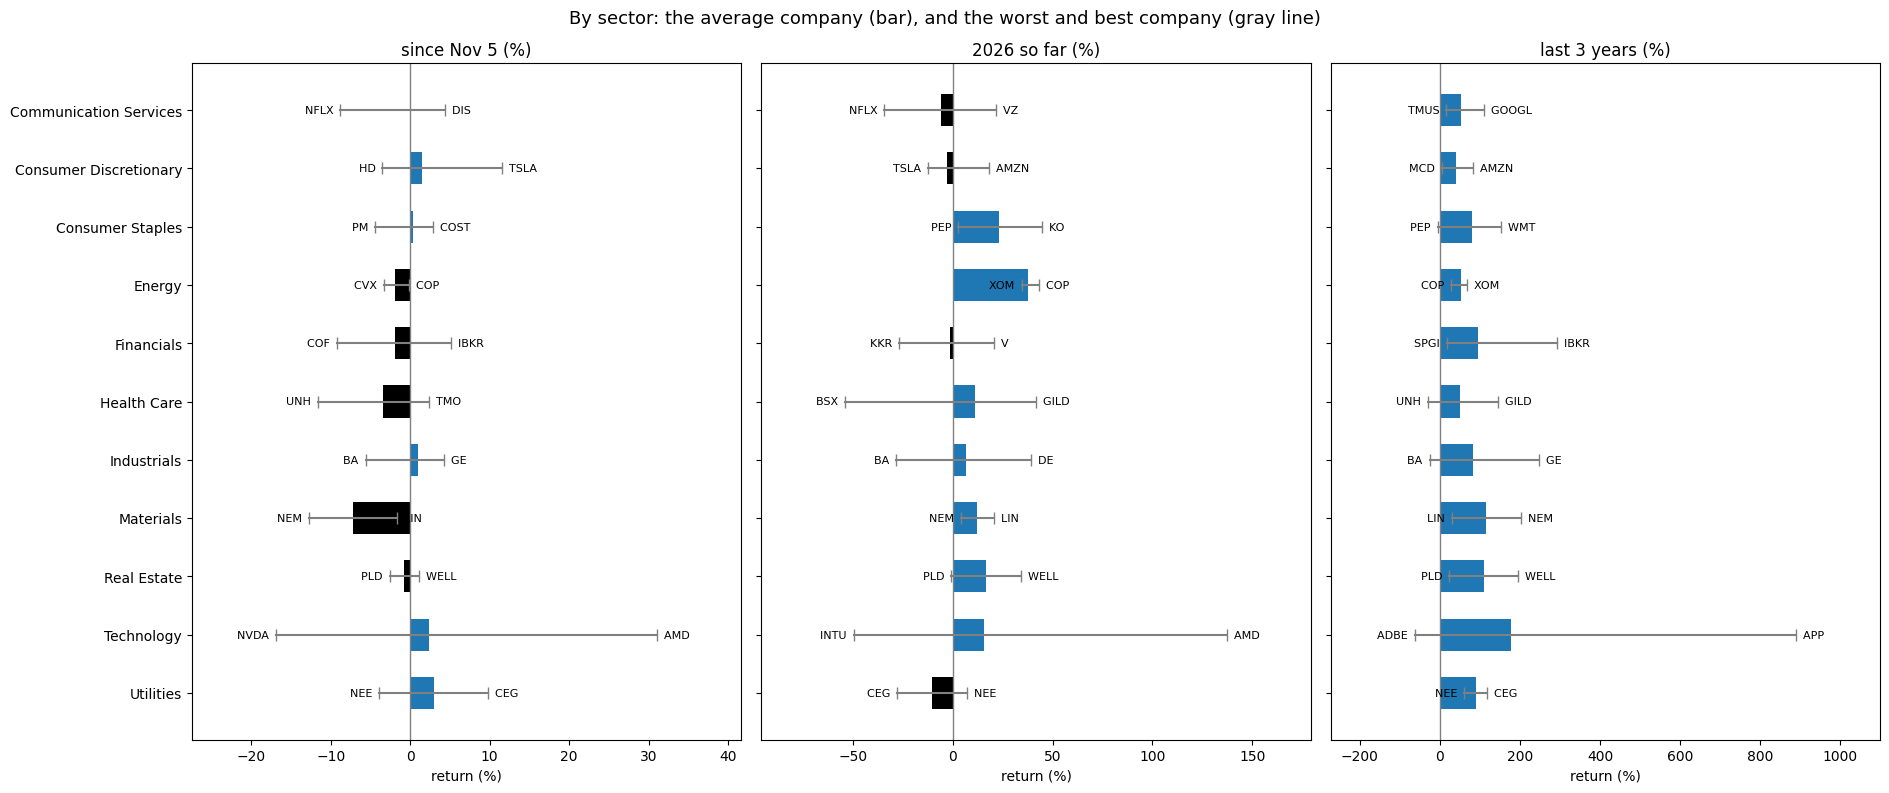

In [ ]:
fig, panels = subplots(1, 3, figsize=(19, 0.55 * len(sectors) + 2), sharey=True)
for p in range(3):
    column = pictures[p][0]
    for i in range(len(sectors)):
        row = menu[menu['sector'] == sectors[i]][column].dropna()

        # the bar: the average company in this sector (blue if it rose, black if it fell)
        color = 'tab:blue'
        if row.mean() < 0:
            color = 'black'
        panels[p].barh(i, row.mean(), color=color, height=0.55)

        # the gray line: from the sector's worst company to its best, with their tickers
        panels[p].plot([row.min(), row.max()], [i, i], color='gray', linewidth=1.5, marker='|', markersize=9)
        panels[p].text(row.max(), i, '  ' + row.idxmax(), va='center', ha='left', fontsize=8)
        panels[p].text(row.min(), i, row.idxmin() + '  ', va='center', ha='right', fontsize=8)

    panels[p].axvline(0, color='gray', linewidth=1)
    panels[p].margins(x=0.22)                  # room for the tickers at the ends
    panels[p].set_title(column)
    panels[p].set_xlabel('return (%)')
panels[0].set_yticks(np.arange(len(sectors)))
panels[0].set_yticklabels(sectors)
panels[0].invert_yaxis()
fig.suptitle('By sector: the average company (bar), and the worst and best company (gray line)', fontsize=13)
tight_layout()
show()

**Read the bars.** Which sector has the longest gray line since Nov 5? Picking a sector is not the same as picking
a stock: inside one sector, some companies rose a lot and others fell a lot.

### The same companies as a table

The best and the worst of the menu, by any column you like. Change `sort_by` to another column name and run the cell
again. `how_many` is the number of rows to show from each end.

In [ ]:
# the column to sort by: 'since Nov 5 (%)', '2026 so far (%)', 'last 3 years (%)', 'average monthly return, 5 years (%)',
# 'average monthly return, 1 year (%)', 'monthly swing, 5 years (%)' or 'monthly swing, 1 year (%)'
sort_by = 'since Nov 5 (%)'
how_many = 15

look = menu.sort_values(sort_by, ascending=False)
top_and_bottom = pd.concat([look.head(how_many), look.tail(how_many)])

print("The %d best and the %d worst of the %d, by: %s" % (how_many, how_many, len(menu), sort_by))
top_and_bottom.style.background_gradient(cmap='RdYlBu', subset=['since Nov 5 (%)'], vmin=-15, vmax=15) \
    .background_gradient(cmap='RdYlBu', subset=['2026 so far (%)'], vmin=-60, vmax=60) \
    .background_gradient(cmap='RdYlBu', subset=['last 3 years (%)'], vmin=-150, vmax=150) \
    .format(precision=1)

The 15 best and the 15 worst of the 100, by: since Nov 5 (%)


,company,sector,since Nov 5 (%),2026 so far (%),last 3 years (%),"average monthly return, 5 years (%)","average monthly return, 1 year (%)","monthly swing, 5 years (%)","monthly swing, 1 year (%)"
ticker,,,,,,,,,
AMD,Advanced Micro Devices,Technology,31.1,137.2,336.2,4.2,8.8,20.2,28.5
ANET,Arista Networks,Technology,21.9,45.2,260.2,3.9,1.6,12.1,15.4
AVGO,Broadcom,Technology,21.4,2.4,267.3,3.9,-0.3,12.1,13.2
LRCX,Lam Research,Technology,14.3,14.7,201.8,3.5,5.8,14.5,21.9
TSLA,"Tesla, Inc.",Consumer Discretionary,11.6,-12.4,62.9,1.5,-0.4,16.9,12.0
AMAT,Applied Materials,Technology,10.4,31.5,136.4,2.8,6.8,14.6,23.9
APP,AppLovin,Technology,9.8,-36.8,889.6,3.9,-6.6,24.3,19.0
CEG,Constellation Energy,Utilities,9.8,-27.8,118.9,3.9,-2.3,13.3,11.4
PANW,Palo Alto Networks,Technology,8.0,89.5,160.9,3.1,5.8,12.1,19.7


# Part 3 - My picks

Now you decide what goes in your final fund. Choose **10 to 25** stocks. The model decides how much of each to buy,
and it may buy none of some, so pick a few more than ten.

There is more than one way to choose, and good managers disagree about which is best. Here are five, and exactly how
this notebook makes a starter list for the first four:

* **Momentum:** buy what has been going up lately.
    * *The list:* the 15 companies on the menu with the best return **since Nov 5**.
    * This is the simplest kind of momentum, two weeks of returns. (Traders also use moving averages, like the 50-day
      and 200-day lines in the bonus momentum notebook. That is a different rule.)
* **Long-run winners:** buy what has gone up the most over a long time.
    * *The list:* the 15 companies with the best return over the **last 3 years**.
* **Bargains:** buy good companies while they are down.
    * *The list:* companies that are **up over the last 3 years** and **down since Nov 5**. Of those, the 15 that
      have fallen the most since Nov 5.
* **Steady:** buy the calmest companies.
    * *The list:* companies that are **up over the last 3 years**. Of those, the 15 with the smallest **monthly
      swing** (standard deviation of monthly returns, 5 years).
* **My own view:** buy the companies or sectors you believe in.
    * *No list and no formula.* Any tickers you choose, for your own reasons: something you saw on the quilt, in the
      news, in a classmate's fund, or a company you know well.

The next cell makes the four lists and prints them. Copy one, mix two, or ignore them.

In [ ]:
# Momentum: the 15 best returns since Nov 5
momentum = list(menu.sort_values('since Nov 5 (%)', ascending=False).head(15).index)

# Long-run winners: the 15 best returns over the last 3 years
long_run = list(menu.sort_values('last 3 years (%)', ascending=False).head(15).index)

# Bargains: up over 3 years AND down since Nov 5; of those, the 15 biggest falls since Nov 5
fallen = menu[(menu['last 3 years (%)'] > 0) & (menu['since Nov 5 (%)'] < 0)]
bargains = list(fallen.sort_values('since Nov 5 (%)').head(15).index)

# Steady: up over 3 years; of those, the 15 with the smallest monthly swing
grown = menu[menu['last 3 years (%)'] > 0]
steady = list(grown.sort_values('monthly swing, 5 years (%)').head(15).index)

print("MOMENTUM: the 15 best returns since Nov 5 (from %+.1f%% down to %+.1f%%)" % (
    menu.loc[momentum[0], 'since Nov 5 (%)'], menu.loc[momentum[-1], 'since Nov 5 (%)']))
print(momentum)
print()
print("LONG-RUN WINNERS: the 15 best returns over 3 years (from %+.0f%% down to %+.0f%%)" % (
    menu.loc[long_run[0], 'last 3 years (%)'], menu.loc[long_run[-1], 'last 3 years (%)']))
print(long_run)
print()
print("BARGAINS: up over 3 years, down since Nov 5 (%d companies qualify; these fell %+.1f%% to %+.1f%% since Nov 5)" % (
    len(fallen), menu.loc[bargains[0], 'since Nov 5 (%)'], menu.loc[bargains[-1], 'since Nov 5 (%)']))
print(bargains)
print()
print("STEADY: up over 3 years, smallest monthly swing (std dev from %.1f%% up to %.1f%% a month)" % (
    menu.loc[steady[0], 'monthly swing, 5 years (%)'], menu.loc[steady[-1], 'monthly swing, 5 years (%)']))
print(steady)

MOMENTUM: the 15 best returns since Nov 5 (from +31.1% down to +4.4%)
['AMD', 'ANET', 'AVGO', 'LRCX', 'TSLA', 'AMAT', 'APP', 'CEG', 'PANW', 'MU', 'ADI', 'TXN', 'IBKR', 'INTC', 'DIS']

LONG-RUN WINNERS: the 15 best returns over 3 years (from +890% down to +163%)
['APP', 'MU', 'PLTR', 'AMD', 'IBKR', 'AVGO', 'ANET', 'GE', 'NEM', 'LRCX', 'NVDA', 'WELL', 'C', 'GS', 'RTX']

BARGAINS: up over 3 years, down since Nov 5 (43 companies qualify; these fell -16.9% to -4.4% since Nov 5)
['NVDA', 'NEM', 'ISRG', 'COF', 'NFLX', 'ABT', 'IBM', 'MRK', 'BMY', 'SPGI', 'MSFT', 'SYK', 'KKR', 'PFE', 'PM']

STEADY: up over 3 years, smallest monthly swing (std dev from 4.8% up to 6.5% a month)
['KO', 'JNJ', 'MCD', 'BRK-B', 'PG', 'CB', 'LIN', 'V', 'TJX', 'MA', 'WMT', 'TMUS', 'VZ', 'DHR', 'UNP']


### 🎯 My picks and my strategy

**This is the most important cell in the notebook: you decide, and you say why.** Edit the list. Tickers go in quotes, with commas between them. Then write your strategy in a few words: it goes on
the leaderboard next to your fund.

In [ ]:
my_picks = ['TSLA', 'ADI', 'TXN', 'APP', 'AVGO', 'NVDA', 'NFLX', 'KKR', 'JNJ', 'TJX']

my_strategy = "mix of: steady names in every sector"      # a few words, in my own words

In [ ]:
# picks that are not on the menu: check each ticker, then download their prices and add them in one step
extra = []
for t in my_picks:
    if t not in sp500.index:
        raise ValueError("%s is not in the S&P 500 table. Check the ticker in my_picks." % t)
    if t not in prices.columns:
        extra.append(t)
if len(extra) > 0:
    more = yf.download(extra, start='2021-09-01', interval='1d', auto_adjust=True, progress=False)['Close']
    if len(extra) == 1:
        more = more.squeeze().to_frame(extra[0])          # one ticker comes back as a single column
    prices = pd.concat([prices, more.reindex(prices.index).ffill()], axis=1)
    month_end = prices.groupby(prices.index.to_period('M')).last()
    month_end = month_end[month_end.index < last_close.to_period('M')]
    monthly = month_end.pct_change(fill_method=None).iloc[1:]
    print("Added prices for:", extra)

# my picks, with their sectors and the same numbers as the menu
rows = []
for t in my_picks:
    row = {}
    row['stock'] = t
    row['company'] = sp500.loc[t, 'company']
    row['sector'] = sp500.loc[t, 'sector']
    row['since Nov 5 (%)'] = round(100 * (prices.loc[last_close, t] / prices.loc[class_start, t] - 1), 1)
    row['last 3 years (%)'] = round(100 * (prices.loc[last_close, t] / prices.loc[three_years_ago, t] - 1), 1)
    # the two numbers the model reads, over 5 years and over 1 year
    row['average monthly return, 5 years (%)'] = round(100 * monthly[t].tail(60).mean(), 2)
    row['monthly swing, 5 years (%)'] = round(100 * monthly[t].tail(60).std(), 2)
    row['average monthly return, 1 year (%)'] = round(100 * monthly[t].tail(12).mean(), 2)
    row['monthly swing, 1 year (%)'] = round(100 * monthly[t].tail(12).std(), 2)
    rows.append(row)
picks = pd.DataFrame(rows).set_index('stock')

print("My strategy:", my_strategy)
print("I picked", len(picks), "stocks in", picks['sector'].nunique(), "sectors.")

# a final fund holds at least 10 stocks, so the notebook stops here until there are at least 10 picks
if len(picks) < 10:
    raise ValueError("Pick at least 10 stocks (a few more is better). Add tickers to my_picks, then run this cell again.")
picks

My strategy: mix of: steady names in every sector
I picked 10 stocks in 5 sectors.


,company,sector,since Nov 5 (%),last 3 years (%),"average monthly return, 5 years (%)","monthly swing, 5 years (%)","average monthly return, 1 year (%)","monthly swing, 1 year (%)"
stock,,,,,,,,
TSLA,"Tesla, Inc.",Consumer Discretionary,11.6,62.9,1.50,16.86,-0.41,11.96
ADI,Analog Devices,Technology,5.8,117.8,1.98,8.82,5.53,10.66
TXN,Texas Instruments,Technology,5.1,104.0,1.48,10.04,6.40,15.17
APP,AppLovin,Technology,9.8,889.6,3.94,24.34,-6.58,19.02
AVGO,Broadcom,Technology,21.4,267.3,3.88,12.12,-0.26,13.22
NVDA,Nvidia,Technology,-16.9,200.4,4.53,14.39,0.42,8.18
NFLX,Netflix,Communication Services,-8.8,26.1,0.76,13.11,-4.31,10.26
KKR,KKR & Co.,Financials,-4.7,40.0,0.98,11.37,-1.18,11.30
JNJ,Johnson & Johnson,Health Care,0.1,96.5,1.23,5.11,3.47,5.92


**Look at the last four columns.** The model reads two numbers for each stock: its average monthly return and its monthly
swing (standard deviation). Both can be very different over 5 years and over 1 year. The model only sees the stretch
you tell it to read (`fit_years`, in the next part).

# Part 4 - Solve

Ms. Womack's model with your business rules: the highest average return for the risk you allow.

$$
\begin{aligned}
\max \quad & \sum_k \bar r_k \, x_k && \text{(average return)} \\
\text{subject to} \quad & \sum_k x_k = 1 && \text{(invest all of the money)} \\
& \sum_i \sum_j x_i \, \sigma_{ij} \, x_j \le \text{risk limit} && \text{(Ms. Womack's risk)} \\
& x_k \ge \text{floor} \cdot y_k && \text{(minimum allocation: if I hold a stock, at least the floor)} \\
& x_k \le \text{cap} \cdot y_k && \text{(maximum allocation: never more than the cap)} \\
& y_k \in \{0, 1\} && \text{(hold stock } k \text{: yes or no)} \\
& \sum_k y_k \ge 10 && \text{(at least 10 stocks)}
\end{aligned}
$$

The next cell is the model as a function: the Studio 5 model with the rules above. It reads your picks' ingredients
(`df_return`, `df_cov`) and your `settings`, and returns the mix it chose. Run it once.

In [ ]:
def solve_portfolio(risk_limit, use_rules):

    # ---- PART 1: the concrete model
    model = ConcreteModel()

    # ---- PART 2: the decision variables
    # x: how much of the money goes in each stock (a share between 0 and 1)
    model.x = Var(stocks, domain=NonNegativeReals, bounds=(0, 1))
    for s in stocks:
        model.x[s] = 1 / len(stocks)               # a starting guess for the solver: an even split

    # y: do we hold stock s? 1 = yes, 0 = no (only needed for the business rules)
    if use_rules:
        model.y = Var(stocks, domain=Binary)
        for s in stocks:
            model.y[s] = 1                         # a starting guess: hold everything

    # ---- PART 3: the objective function
    # the fund's return: each stock's average monthly return, weighted by its share
    return_expr = 0
    for s in stocks:
        return_expr += df_return[s] * model.x[s]

    # the fund's risk (Ms. Womack's): the weighted covariance matrix, summed
    risk_expr = 0
    for i in stocks:
        for j in stocks:
            risk_expr += model.x[i] * df_cov.loc[i, j] * model.x[j]

    if risk_limit is None:
        # no risk limit given: find the SAFEST fund, the one with the lowest risk.
        # Step 2 does this once, to find where the efficient frontier starts.
        model.goal = Objective(expr=risk_expr, sense=minimize)
    else:
        # the usual case: the highest return
        model.goal = Objective(expr=return_expr, sense=maximize)

    # ---- PART 4: the constraints
    model.constraints = ConstraintList()

    # invest all of the money
    budget = 0
    for s in stocks:
        budget += model.x[s]
    model.constraints.add(budget == 1)

    # the risk stays under the risk limit
    if risk_limit is not None:
        model.constraints.add(risk_expr <= risk_limit)

    # my business rules (they come from `settings`)
    if use_rules:
        held = 0
        for s in stocks:
            model.constraints.add(model.x[s] >= settings['min_share'] * model.y[s])      # minimum allocation
            model.constraints.add(model.x[s] <= settings['max_share'] * model.y[s])      # maximum allocation
            held += model.y[s]
        model.constraints.add(held >= settings['min_stocks'])                            # at least this many stocks

    # ---- PART 5: solve it (Bonmin when there are yes/no variables, ipopt when there are not)
    if use_rules:
        results = SolverFactory('bonmin', executable=bonmin_path).solve(model)
    else:
        results = SolverFactory('ipopt', executable=ipopt_path).solve(model)
    if results.solver.termination_condition != TerminationCondition.optimal:
        return None

    # hand back the stocks the model actually holds (more than 0.1% of the money)
    mix = {}
    for s in stocks:
        if model.x[s]() > 0.001:
            mix[s] = round(model.x[s](), 6)
    return {'mix': mix, 'return': value(return_expr), 'risk': value(risk_expr)}


print("solve_portfolio is ready")

solve_portfolio is ready


### 🎯 My settings

These five numbers are yours. The model function above reads them every time it solves.

* `fit_years`: how many years of monthly returns the model reads. A short history reacts to recent news; a long one
  is steadier.
* `max_share`: the cap, as a fraction. `0.25` means **25%**: no stock gets more than a quarter of your money.
* `min_share`: the floor, as a fraction. `0.02` means **2%**: if the model buys a stock, it buys at least that much.
* `min_stocks`: the fewest stocks your fund may hold.
* `max_swing`: **the risk limit**, in percent. See below.

**What is `max_swing`?** In Studio 5 the risk limit was a variance, a small number like 0.0025 that is hard to picture.
Take its square root and you get a **standard deviation**: 0.05, or **5% a month**. That is the swing: how far a
typical month lands from the fund's average monthly return. `max_swing = 5.0` tells the model "find me the best fund whose
monthly swing is 5% or less". A bigger number lets the model take more risk.

Leave `max_swing` as `None` the first time. The notebook then finds **the corner of your efficient frontier** in
Step 2: the fund nearest the top left of the picture, where the return is high and the risk is still low. To choose
your own risk instead, type a number here.

In [ ]:
settings = {
    'fit_years': 5,        # read 5 years of monthly returns (try 3 or 1)
    'max_share': 0.25,     # the cap: 0.25 = at most 25% in one stock (0.25 is the most allowed)
    'min_share': 0.02,     # the floor: 0.02 = at least 2% in any stock I hold
    'min_stocks': 10,      # hold at least 10 stocks (10 is the fewest allowed)
    'max_swing': None,     # the risk limit: my fund's monthly swing (standard deviation) in %, for example 5.5.
                           # None = let the notebook find the corner of my efficient frontier (Step 2)
}

**Check my settings against the final-fund rules.** A final fund holds at least 10 stocks and puts at most 25% in
any one. This cell only checks; it changes nothing.

In [ ]:
if settings['max_share'] > 0.25:
    raise ValueError("max_share is %.2f. The most allowed is 0.25 (25%% in one stock). Change it in My settings." % settings['max_share'])
if settings['min_stocks'] < 10:
    raise ValueError("min_stocks is %d. The fewest allowed is 10. Change it in My settings." % settings['min_stocks'])

print("My settings keep the final-fund rules:")
print("   the model reads %d year(s) of monthly returns" % settings['fit_years'])
print("   at most %.0f%% in one stock, at least %.0f%% in any stock I hold" % (100 * settings['max_share'], 100 * settings['min_share']))
print("   at least %d stocks" % settings['min_stocks'])
if settings['max_swing'] is None:
    print("   risk limit: the corner of my efficient frontier (found in Step 2)")
else:
    print("   risk limit: a monthly swing of %.1f%%" % settings['max_swing'])

My settings keep the final-fund rules:
   the model reads 5 year(s) of monthly returns
   at most 25% in one stock, at least 2% in any stock I hold
   at least 10 stocks
   risk limit: the corner of my efficient frontier (found in Step 2)


### Step 1 - The model's two ingredients

Each pick's **average monthly return** (`df_return`) and the **covariance matrix** (`df_cov`), from the months you told the
model to read. A pick that has not traded for that whole stretch is dropped automatically, and the cell says so.

Then two yardsticks, in the same units: the average monthly return and the monthly swing of **an even split of your picks**,
and of the **S&P 500**. They show up again in Step 2, as the black dot and the black square on the frontier.

A fund's swing comes from the covariance matrix, as in Studio 5:
$\text{swing} = \sqrt{\sum_i \sum_j x_i \, \sigma_{ij} \, x_j}$. The model's risk limit is that number squared.

In [ ]:
# monthly returns for my picks, the last fit_years years (fit_years comes from My settings)
returns = monthly[list(picks.index)].tail(12 * settings['fit_years'])

# a pick that has not traded for that whole history gives the model nothing to read: drop it and carry on
dropped = []
for t in returns.columns:
    if returns[t].isna().sum() > 0:
        dropped.append(t)
returns = returns.drop(columns=dropped)
stocks = list(returns.columns)

if len(dropped) > 0:
    print("Dropped automatically:", dropped)
    print("   No full %d-year history to read for these, so the model carries on with my other %d picks." % (settings['fit_years'], len(stocks)))
    print("   (To keep them, use a shorter fit_years in My settings.)")
    print()

# after dropping, there must still be enough picks to hold the fewest stocks my fund needs
if len(stocks) < settings['min_stocks']:
    raise ValueError("Only %d of my picks have %d year(s) of history, and my fund needs at least %d stocks. "
                     "Add picks in Part 3, or use a shorter fit_years in My settings." % (len(stocks), settings['fit_years'], settings['min_stocks']))

# the two ingredients
df_return = returns.mean()
df_cov = returns.cov()

# yardstick 1: an even split of my picks (the same share in every pick)
even_return = 0
even_variance = 0
for i in stocks:
    even_return += df_return[i] / len(stocks)
    for j in stocks:
        even_variance += df_cov.loc[i, j] / len(stocks) ** 2
even_swing = 100 * np.sqrt(even_variance)          # the standard deviation, in % a month

# yardstick 2: the S&P 500 over the same months
spy_months = monthly['SPY'].tail(12 * settings['fit_years'])
spy_average = 100 * spy_months.mean()
spy_swing = 100 * spy_months.std()

print("The model reads %d months (%s to %s) for %d picks." % (len(returns), returns.index[0], returns.index[-1], len(stocks)))
print()
print("                              average monthly return    monthly swing")
print("An even split of my picks:            %5.2f%%               %5.2f%%" % (100 * even_return, even_swing))
print("The S&P 500:                          %5.2f%%               %5.2f%%" % (spy_average, spy_swing))

The model reads 60 months (2021-11 to 2026-10) for 10 picks.

                              average monthly return    monthly swing
An even split of my picks:             2.19%                7.69%
The S&P 500:                           1.04%                4.46%


#### Where does a swing number come from?

Take the even split of your picks. In each month its return is simply the **average of your picks' returns that
month**. That gives one number per month. Their **average** is the fund's average monthly return, and their **standard
deviation** is its swing: how far a typical month lands from the average.

The picture shows those monthly returns as bars. The solid line is the average monthly return, and the two dashed lines are
one swing above it and one swing below it. Most months land between the dashed lines.

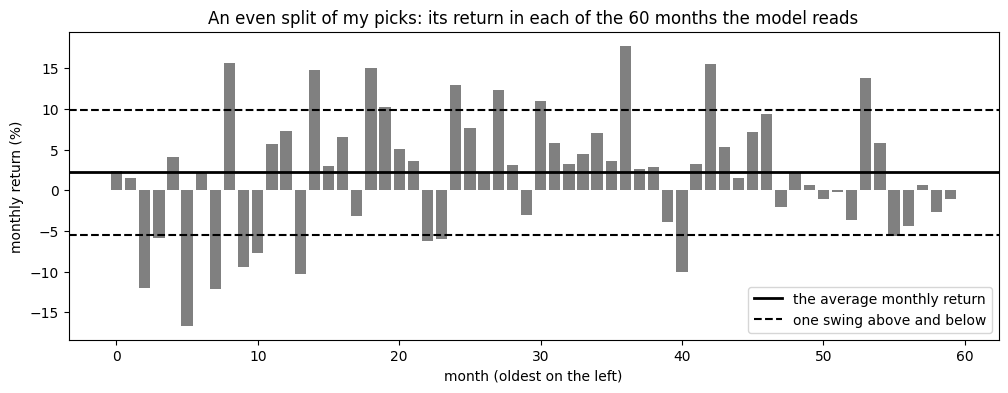

An even split of my picks, over 60 months:
   average monthly return:                    2.19%
   swing (standard deviation of the months):  7.69%
   the same swing from the covariance matrix: 7.69%  (the square root of the risk in Ms. Womack's model)
   39 of the 60 months landed within one swing of the average

The S&P 500 is done the same way with its own monthly returns: average 1.04%, swing 4.46%.


In [ ]:
# the even split's return in each month: the average of my picks' returns that month
even_months = returns.mean(axis=1)

fig, panel = subplots(figsize=(12, 4))
panel.bar(range(len(even_months)), 100 * even_months.values, color='gray')
panel.axhline(100 * even_months.mean(), color='black', linewidth=2, label='the average monthly return')
panel.axhline(100 * (even_months.mean() + even_months.std()), color='black', linestyle='--', linewidth=1.5, label='one swing above and below')
panel.axhline(100 * (even_months.mean() - even_months.std()), color='black', linestyle='--', linewidth=1.5)
panel.set_title("An even split of my picks: its return in each of the %d months the model reads" % len(even_months))
panel.set_ylabel('monthly return (%)')
panel.set_xlabel('month (oldest on the left)')
panel.legend()
show()

inside = ((even_months - even_months.mean()).abs() <= even_months.std()).sum()
print("An even split of my picks, over %d months:" % len(even_months))
print("   average monthly return:                    %.2f%%" % (100 * even_months.mean()))
print("   swing (standard deviation of the months):  %.2f%%" % (100 * even_months.std()))
print("   the same swing from the covariance matrix: %.2f%%  (the square root of the risk in Ms. Womack's model)" % even_swing)
print("   %d of the %d months landed within one swing of the average" % (inside, len(even_months)))
print()
print("The S&P 500 is done the same way with its own monthly returns: average %.2f%%, swing %.2f%%." % (spy_average, spy_swing))

### Step 2 - The efficient frontier

The efficient frontier is the best fund at every level of risk. To draw all of it, we need to know where it starts
and where it ends:

* **the safest fund:** the lowest risk your picks and your rules allow. Nothing sits to the left of it.
* **the highest-return fund:** the most return your rules allow, whatever the risk. Nothing sits above it.

In [ ]:
# the two ends of the frontier, with my rules
safest = solve_portfolio(None, use_rules=True)       # no risk limit given: the model finds the lowest risk
boldest = solve_portfolio(1.0, use_rules=True)       # a risk limit so big it never matters: the highest return

if safest is None or boldest is None:
    raise ValueError("No fund fits my rules with these picks. Add picks in Part 3, then run Part 4 again from Step 1.")

low_swing = 100 * np.sqrt(safest['risk'])            # the risk is a variance: its square root is the monthly swing
high_swing = 100 * np.sqrt(boldest['risk'])

print("                              average monthly return    monthly swing    stocks held")
print("The safest fund:                      %5.2f%%               %5.2f%%           %d" % (100 * safest['return'], low_swing, len(safest['mix'])))
print("The highest-return fund:              %5.2f%%               %5.2f%%           %d" % (100 * boldest['return'], high_swing, len(boldest['mix'])))
print()
print("So my frontier runs from a monthly swing of %.2f%% to %.2f%%." % (low_swing, high_swing))

                              average monthly return    monthly swing    stocks held
The safest fund:                       1.82%                4.94%           10
The highest-return fund:               3.50%               11.06%           10

So my frontier runs from a monthly swing of 4.94% to 11.06%.


Now solve the model at **eight risk limits**, evenly spaced from the safest fund's swing to the highest-return
fund's swing. Each solve is a whole portfolio. We do it twice: with your rules (blue) and with no rules (gray).

About 30 seconds: the blue line needs Bonmin, because of the yes/no variables.

In [ ]:
# eight limits on the monthly swing, in %, from the safest fund to the highest-return fund
# (a hair above each end, so rounding never puts a limit out of reach)
swings = np.round(np.linspace(low_swing + 0.01, high_swing + 0.01, 8), 2)

frontier = {}          # swing limit -> the fund with my rules at that limit (None if nothing fits)
free_frontier = {}     # swing limit -> the same with no rules
for swing in swings:
    variance_limit = (swing / 100) ** 2                     # the model's risk limit is the swing, squared
    frontier[swing] = solve_portfolio(variance_limit, use_rules=True)
    free_frontier[swing] = solve_portfolio(variance_limit, use_rules=False)

# one row per limit: what each fund reaches
rows = []
for swing in swings:
    row = {'swing limit (% a month)': swing}
    if frontier[swing] is not None:
        row['with my rules: average monthly return (%)'] = round(100 * frontier[swing]['return'], 2)
        row['with my rules: number of stocks held'] = len(frontier[swing]['mix'])
    if free_frontier[swing] is not None:
        row['no rules: average monthly return (%)'] = round(100 * free_frontier[swing]['return'], 2)
        row['no rules: number of stocks held'] = len(free_frontier[swing]['mix'])
    rows.append(row)
frontier_table = pd.DataFrame(rows).set_index('swing limit (% a month)')
frontier_table

,with my rules: average monthly return (%),with my rules: number of stocks held,no rules: average monthly return (%),no rules: number of stocks held
swing limit (% a month),,,,
4.95,1.90,10,2.42,5
5.82,2.53,10,2.72,5
6.70,2.81,10,2.99,4
7.57,2.99,10,3.23,3
8.45,3.13,10,3.46,3
9.32,3.26,10,3.67,3
10.20,3.39,10,3.89,3
11.07,3.50,10,4.10,3


#### The corner of the frontier

Which of these eight funds should be yours? Look for the **top left corner** of the frontier: as much return as you
can get before extra risk stops paying. Past the corner, the line flattens: you take more risk and get little for it.

To find it, put risk and return on the same 0-to-1 scale (0 = the lowest on the blue line, 1 = the highest). The
perfect fund would sit at the top left of the picture: risk 0, return 1. No fund gets there, so we take the one that
is **closest**.

In [ ]:
# every fund on the blue line: its risk (monthly swing) and its return (average monthly return)
rows = []
for swing in swings:
    if frontier[swing] is not None:
        row = {}
        row['swing limit (% a month)'] = swing
        row['risk: monthly swing (%)'] = round(100 * np.sqrt(frontier[swing]['risk']), 2)
        row['return: average monthly return (%)'] = round(100 * frontier[swing]['return'], 2)
        rows.append(row)
corner_table = pd.DataFrame(rows).set_index('swing limit (% a month)')

# the same 0-to-1 scale for both, so risk and return count the same
# (if every fund has the same number there is nothing to scale: call it 0)
risk = corner_table['risk: monthly swing (%)']
reward = corner_table['return: average monthly return (%)']
corner_table['risk, 0 to 1'] = ((risk - risk.min()) / (risk.max() - risk.min())).fillna(0)
corner_table['return, 0 to 1'] = ((reward - reward.min()) / (reward.max() - reward.min())).fillna(0)

# how far each fund sits from the top left of the picture (risk 0, return 1): a straight-line distance
across = corner_table['risk, 0 to 1']
down = 1 - corner_table['return, 0 to 1']
corner_table['distance from the top left'] = np.sqrt(across ** 2 + down ** 2)

# the corner is the fund with the smallest distance
corner_swing = float(corner_table['distance from the top left'].idxmin())

print("The corner of my frontier: a swing limit of %.2f%% a month." % corner_swing)
print("   that fund's average monthly return: %.2f%%" % corner_table.loc[corner_swing, 'return: average monthly return (%)'])
print("   that fund's monthly swing:          %.2f%%" % corner_table.loc[corner_swing, 'risk: monthly swing (%)'])
print()
if settings['max_swing'] is None:
    print("max_swing is None in My settings, so Step 3 builds my fund at the corner.")
else:
    print("I typed max_swing = %.2f in My settings, so Step 3 uses my number, not the corner." % settings['max_swing'])
corner_table.round(2)

The corner of my frontier: a swing limit of 6.70% a month.
   that fund's average monthly return: 2.81%
   that fund's monthly swing:          6.70%

max_swing is None in My settings, so Step 3 builds my fund at the corner.


,risk: monthly swing (%),return: average monthly return (%),"risk, 0 to 1","return, 0 to 1",distance from the top left
swing limit (% a month),,,,,
4.95,4.95,1.90,0.00,0.00,1.00
5.82,5.82,2.53,0.14,0.39,0.62
6.70,6.70,2.81,0.29,0.57,0.52
7.57,7.57,2.99,0.43,0.68,0.53
8.45,8.45,3.13,0.57,0.77,0.62
9.32,9.32,3.26,0.72,0.85,0.73
10.20,10.20,3.39,0.86,0.93,0.86
11.07,11.06,3.50,1.00,1.00,1.00


**The two pictures.**

**Left: the frontier.** Every point on this picture is one portfolio, placed by its two numbers over the months the
model read: across is its risk (its monthly swing), up is its average monthly return.

* **The blue line** is your fund at each of the eight risk limits, and the gray line is the same with no rules. The
  gap between them is what your rules cost on paper.
* **The black dot** is an even split of your picks: the same share in every stock. Its two numbers came from Step 1.
* **The black square** is the S&P 500, measured over the same months.
* **The gold star** is the corner of the blue line, from the cell above. If you typed your own `max_swing`, a dashed
  blue line marks it.

The black dot sits **below** the blue line. Read straight up from it: at that same risk, the model's fund had a
higher average monthly return. That is what *efficient* means: no other mix of your picks gave more return for that
much risk. Keep in mind where that comes from. The model set the shares **knowing how those months turned out**, and
you chose these picks knowing it too. The frontier describes the past.

The black square may sit to the **left** of where the blue line starts. The blue line starts at the safest fund your
picks allow, so that means no mix of your picks is as calm as the S&P 500, which spreads its money over 500 companies.

**Right: the allocation** behind the blue line. Each color is a stock and each column is one portfolio. Watch how
the money moves as you allow more risk.

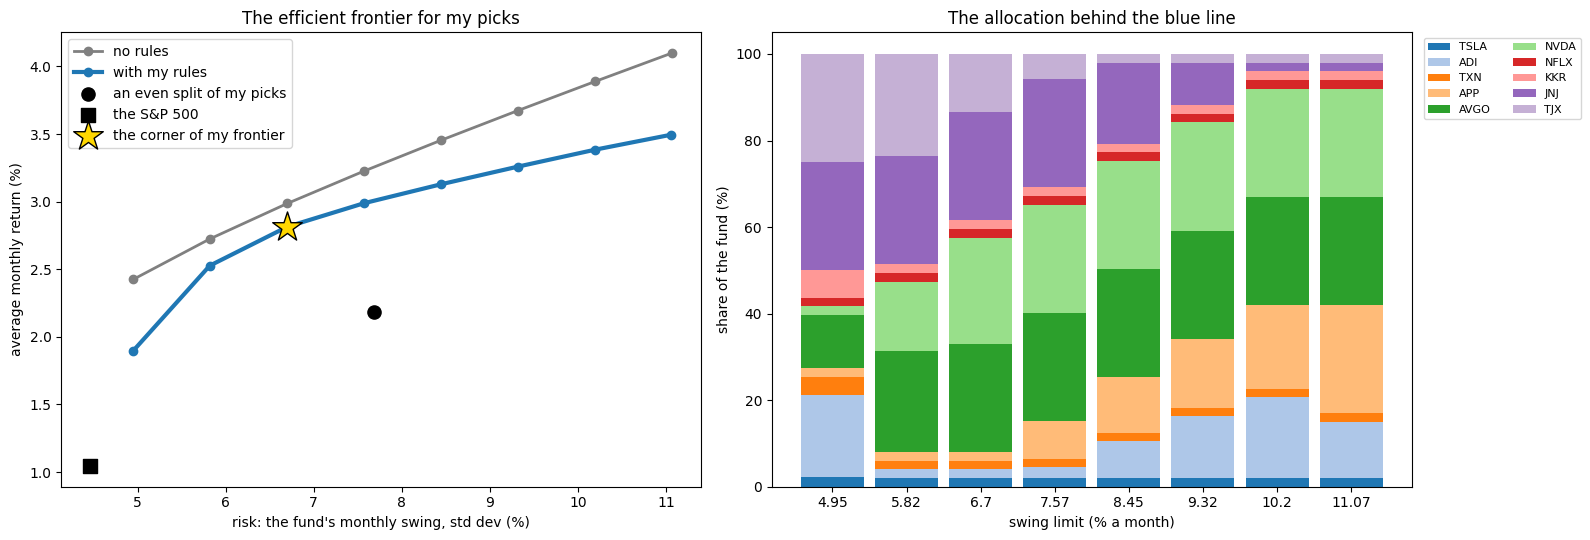

In [ ]:
fig, (left, right) = subplots(1, 2, figsize=(16, 5.5))

# left: the two frontiers. Each point is (the fund's swing, its average monthly return), for the limits that solved.
ruled_x = []
ruled_y = []
free_x = []
free_y = []
solved = []
for swing in swings:
    if frontier[swing] is not None:
        ruled_x.append(100 * np.sqrt(frontier[swing]['risk']))
        ruled_y.append(100 * frontier[swing]['return'])
        solved.append(swing)
    if free_frontier[swing] is not None:
        free_x.append(100 * np.sqrt(free_frontier[swing]['risk']))
        free_y.append(100 * free_frontier[swing]['return'])
left.plot(free_x, free_y, color='gray', marker='o', linewidth=2, label='no rules')
left.plot(ruled_x, ruled_y, color='tab:blue', marker='o', linewidth=3, label='with my rules')
left.scatter([even_swing], [100 * even_return], color='black', s=90, zorder=5, label='an even split of my picks')
left.scatter([spy_swing], [spy_average], color='black', marker='s', s=90, zorder=5, label='the S&P 500')

# the corner of the blue line, and my own limit if I typed one
corner_x = corner_table.loc[corner_swing, 'risk: monthly swing (%)']
corner_y = corner_table.loc[corner_swing, 'return: average monthly return (%)']
left.scatter([corner_x], [corner_y], color='gold', edgecolor='black', marker='*', s=500, zorder=6, label='the corner of my frontier')
if settings['max_swing'] is not None:
    left.axvline(settings['max_swing'], color='tab:blue', linestyle='--', linewidth=1.5, label='my own max_swing')
left.set_xlabel("risk: the fund's monthly swing, std dev (%)")
left.set_ylabel('average monthly return (%)')
left.set_title('The efficient frontier for my picks')
left.legend()

# right: the allocation with my rules, one stacked column for each swing limit that solved
bottom = np.zeros(len(solved))
shade = 0
for t in stocks:
    heights = []
    for swing in solved:
        heights.append(100 * frontier[swing]['mix'].get(t, 0))
    if max(heights) > 0:
        right.bar(range(len(solved)), heights, bottom=bottom, label=t, width=0.85, color=cm.tab20(shade % 20))
        bottom = bottom + np.array(heights)
        shade += 1
right.set_xticks(range(len(solved)))
right.set_xticklabels(solved)
right.set_xlabel('swing limit (% a month)')
right.set_ylabel('share of the fund (%)')
right.set_title('The allocation behind the blue line')
right.legend(fontsize=8, ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
tight_layout()
show()

### Step 3 - My fund

One solve at your risk limit. If `max_swing` is `None`, that is the corner of the frontier (the gold star). To choose
your own, look at the frontier, put a number in `max_swing` in **My settings**, and run Part 4 again from Step 1.

In [ ]:
# my risk: the swing I typed in My settings, or the corner of the frontier
my_swing = settings['max_swing']
if my_swing is None:
    my_swing = corner_swing
risk_limit = (my_swing / 100) ** 2                       # the model's risk limit is the swing, squared

fund = solve_portfolio(risk_limit, use_rules=True)       # my fund
twin = solve_portfolio(risk_limit, use_rules=False)      # its no-rules twin (the leaderboard tracks both)

# nothing fits at this level of risk: stop here, so the cells below do not run on a fund that does not exist
if fund is None or twin is None:
    raise ValueError("No fund fits with a swing of %.1f%% a month. Look at the frontier: put a bigger number in max_swing "
                     "(or None), then run Part 4 again from Step 1." % my_swing)

my_mix = fund['mix']

# my fund as a table, biggest share first
rows = []
for t in sorted(my_mix, key=my_mix.get, reverse=True):
    row = {}
    row['stock'] = t
    row['company'] = picks.loc[t, 'company']
    row['sector'] = picks.loc[t, 'sector']
    row['share of my fund (%)'] = round(100 * my_mix[t], 1)
    row['average monthly return the model read (%)'] = round(100 * df_return[t], 2)
    row['monthly swing the model read (%)'] = round(100 * returns[t].std(), 2)
    rows.append(row)
my_fund = pd.DataFrame(rows).set_index('stock')

# the picks the model left out
left_out = []
for t in stocks:
    if t not in my_mix:
        left_out.append(t)

print("                              average monthly return    monthly swing")
print("My final fund:                        %5.2f%%               %5.2f%%   (my limit: %.2f%%)" % (100 * fund['return'], 100 * np.sqrt(fund['risk']), my_swing))
print("An even split of my picks:            %5.2f%%               %5.2f%%" % (100 * even_return, even_swing))
print("The S&P 500:                          %5.2f%%               %5.2f%%" % (spy_average, spy_swing))
print()
print("My fund holds %d stocks. Biggest share: %.0f%%." % (len(my_mix), 100 * max(my_mix.values())))
print("Picks the model did not buy:", left_out)
print("With no rules the model would hold only", len(twin['mix']), "stocks.")
my_fund

                              average monthly return    monthly swing
My final fund:                         2.81%                6.70%   (my limit: 6.70%)
An even split of my picks:             2.19%                7.69%
The S&P 500:                           1.04%                4.46%

My fund holds 10 stocks. Biggest share: 25%.
Picks the model did not buy: []
With no rules the model would hold only 4 stocks.


,company,sector,share of my fund (%),average monthly return the model read (%),monthly swing the model read (%)
stock,,,,,
AVGO,Broadcom,Technology,25.0,3.88,12.12
JNJ,Johnson & Johnson,Health Care,25.0,1.23,5.11
NVDA,Nvidia,Technology,24.5,4.53,14.39
TJX,TJX Companies,Consumer Discretionary,13.5,1.58,5.99
TSLA,"Tesla, Inc.",Consumer Discretionary,2.0,1.50,16.86
ADI,Analog Devices,Technology,2.0,1.98,8.82
TXN,Texas Instruments,Technology,2.0,1.48,10.04
APP,AppLovin,Technology,2.0,3.94,24.34
NFLX,Netflix,Communication Services,2.0,0.76,13.11


**How would this mix have done?** \$10,000 in today's mix since the first trading day of 2026, next to the S&P 500.
This is hindsight: you picked these stocks already knowing how 2026 went. The red line is Nov 5.

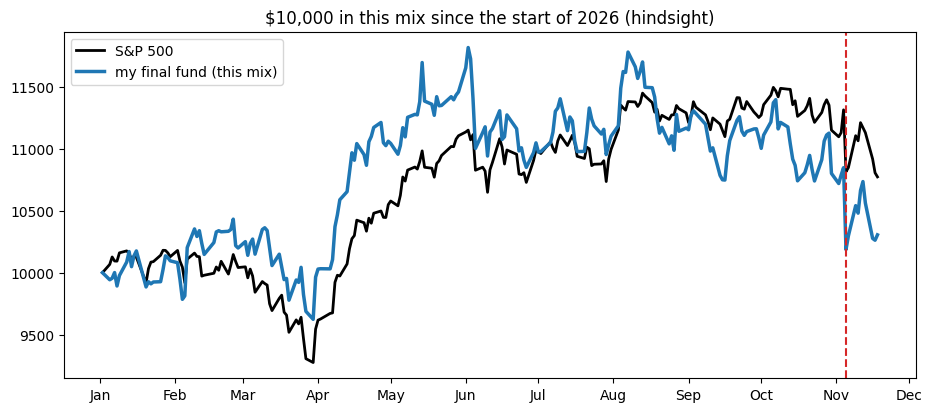

2026 so far: this mix turned $10,000 into $10305. The S&P 500: $10772.
Since Nov 05: this mix +1.2%, the S&P 500 -0.4%.


In [ ]:
this_year = hold(my_mix, year_start)
market_year = hold({'SPY': 1.0}, year_start)

fig, panel = subplots(figsize=(11, 4.5))
panel.plot(market_year.index, market_year.values, color='black', linewidth=2, label='S&P 500')
panel.plot(this_year.index, this_year.values, color='tab:blue', linewidth=2.5, label='my final fund (this mix)')
panel.axvline(class_start, color='tab:red', linestyle='--', linewidth=1.5)
panel.set_title('$10,000 in this mix since the start of 2026 (hindsight)')
panel.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
panel.legend()
show()

print("2026 so far: this mix turned $10,000 into $%.0f. The S&P 500: $%.0f." % (this_year.iloc[-1], market_year.iloc[-1]))
print("Since %s: this mix %+.1f%%, the S&P 500 %+.1f%%." % (
    class_start.strftime('%b %d'), 100 * (this_year.iloc[-1] / this_year.loc[class_start] - 1), spy_return))

### 🎯 Try things

This is where you experiment. Change one thing, run it again, and see what your fund does. Try at least three
changes before you settle on your final fund.

**How:** change your picks (in **My picks and my strategy**) or a number in **My settings**. Then click the cell you
changed and choose Runtime, **Run cell and below**. Your new fund and its 2026 chart show up in about a minute. The
run then goes on to the news in Part 5; press the stop button if you do not need the news yet.

Things to try:

* Set `fit_years` to 1. Which stocks does the model drop, and which does it add?
* Lower the cap `max_share` to 0.15. How much average monthly return does that cost you?
* Type your own `max_swing`: a little more than the corner's, then a little less. What does the model do with the
  money?
* Swap your picks for the `momentum` list, then `bargains`, then `steady`. Which fund would you rather own for the
  next two weeks, and why?

Keep a note of what you tried and what changed. We will talk about it as a class: who picked what, why, and which
change moved your fund the most.

When you have the fund you want, go on.

# Part 5 - The news (optional)

Numbers say what happened. The news says why, and what might happen next. This part collects the news for every
stock in your fund, scores its tone, and saves it all in **one PDF** you can read yourself or hand to Claude.

For each stock it gathers:

* the **headlines since Nov 5** (from Google News), and
* the **latest stories** (from Yahoo Finance's news feed), each with its one-line summary, its link, and **the
  opening of the article** where the news site allows it. Some sites do not let a program read their pages; those
  stories keep only the summary.

### Step 1 - Two small tools

`fpdf2` writes PDF files and `vaderSentiment` scores the tone of a sentence. The function `article_opening` opens a
news page and returns the start of its text.

In [ ]:
if 'google.colab' in sys.modules:
    !pip install -q fpdf2 vaderSentiment

from bs4 import BeautifulSoup
from fpdf import FPDF
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib

# news sites answer a program more readily when it says which browser it is
browser = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120 Safari/537.36'}


def article_opening(link, how_much=1200):
    # open a news page and return the first `how_much` characters of its text ('' if the site says no)
    try:
        page = requests.get(link, headers=browser, timeout=15)
        if page.status_code != 200:
            return ''
        soup = BeautifulSoup(page.text, 'html.parser')
        text = ''
        for paragraph in soup.find_all('p'):
            words = paragraph.get_text(' ', strip=True)
            if len(words) > 80:               # skip menus, captions and other short bits
                text += words + ' '
        return text[:how_much]
    except Exception as problem:
        return ''


print("ready")

ready


### Step 2 - Gather the news

About a minute: it opens a few news pages for every stock.

In [ ]:
stories_per_stock = 3          # how many of the latest stories to open for each stock
since = class_start.strftime('%Y-%m-%d')

news = {}                      # stock -> its headlines and its latest stories
opened = 0
for t in my_fund.index:
    name = my_fund.loc[t, 'company']
    news[t] = {'headlines': [], 'stories': []}

    # 1. headlines since Nov 5, from Google News
    search = '%s stock after:%s' % (name, since)
    link = 'https://news.google.com/rss/search?q=' + requests.utils.quote(search) + '&hl=en-US&gl=US&ceid=US:en'
    try:
        feed = ET.fromstring(requests.get(link, timeout=20).content)
        for item in feed.iter('item'):
            news[t]['headlines'].append({'date': item.findtext('pubDate')[5:16], 'title': item.findtext('title')})
            if len(news[t]['headlines']) == 8:
                break
    except Exception as problem:
        print("Google News did not answer for", t)

    # 2. the latest stories, from Yahoo Finance's news feed for this ticker
    link = 'https://feeds.finance.yahoo.com/rss/2.0/headline?s=%s&region=US&lang=en-US' % t
    try:
        feed = ET.fromstring(requests.get(link, headers=browser, timeout=20).content)
        for item in feed.iter('item'):
            story = {'date': item.findtext('pubDate')[5:16], 'title': item.findtext('title'),
                     'summary': item.findtext('description') or '', 'link': item.findtext('link')}
            story['opening'] = article_opening(story['link'])
            if story['opening'] != '':
                opened += 1
            news[t]['stories'].append(story)
            if len(news[t]['stories']) == stories_per_stock:
                break
    except Exception as problem:
        print("Yahoo Finance's news feed did not answer for", t)

    print("%-6s %d headlines, %d stories" % (t, len(news[t]['headlines']), len(news[t]['stories'])))

print()
print("I could read the opening of", opened, "articles.")

AVGO   8 headlines, 3 stories
JNJ    8 headlines, 3 stories
NVDA   8 headlines, 3 stories
TJX    8 headlines, 3 stories
TSLA   8 headlines, 3 stories
ADI    8 headlines, 3 stories
TXN    8 headlines, 3 stories
APP    8 headlines, 3 stories
Google News did not answer for NFLX
NFLX   0 headlines, 3 stories
KKR    8 headlines, 3 stories

I could read the opening of 20 articles.


### Step 3 - A sentiment score for each stock

**VADER** is a simple, well-known tool that scores the tone of a sentence from **-1** (very negative) to **+1** (very
positive) by looking up its words in a dictionary of positive and negative words. Here each stock's score is the
average over its headlines and story summaries.

It is a blunt instrument: it reads "stock drops" as bad news and has no idea what a tariff is. Use it to decide which
stories to read first, and compare it with what the stock actually did.

In [ ]:
scorer = SentimentIntensityAnalyzer()

rows = []
for t in my_fund.index:
    # every sentence we have about this stock: its headlines, and its stories' titles and summaries
    sentences = []
    for headline in news[t]['headlines']:
        sentences.append(headline['title'])
    for story in news[t]['stories']:
        sentences.append(story['title'] + '. ' + story['summary'])

    # the average tone, and the single most negative headline
    total = 0
    lowest = 0
    lowest_text = ''
    for sentence in sentences:
        tone = scorer.polarity_scores(sentence)['compound']
        total += tone
        if tone < lowest:
            lowest = tone
            lowest_text = sentence
    score = 0
    if len(sentences) > 0:
        score = total / len(sentences)

    news[t]['sentiment'] = round(score, 2)
    rows.append({'stock': t, 'share of my fund (%)': my_fund.loc[t, 'share of my fund (%)'],
                 'return since Nov 5 (%)': picks.loc[t, 'since Nov 5 (%)'], 'news sentiment (-1 to +1)': round(score, 2),
                 'sentences scored': len(sentences), 'most negative headline': lowest_text[:90]})
sentiment = pd.DataFrame(rows).set_index('stock').sort_values('news sentiment (-1 to +1)')

sentiment.style.background_gradient(cmap='RdYlBu', subset=['news sentiment (-1 to +1)'], vmin=-0.5, vmax=0.5) \
    .background_gradient(cmap='RdYlBu', subset=['return since Nov 5 (%)'], vmin=-15, vmax=15).format(precision=2)

,share of my fund (%),return since Nov 5 (%),news sentiment (-1 to +1),sentences scored,most negative headline
stock,,,,,
NFLX,2.00,-8.80,-0.02,3,Josh Brown Says Netflix Trades at 16 Times Next Year’s Earnings After a 50% Drop. Is It a
NVDA,24.50,-16.90,0.00,11,Stock Market Today: Dow Ends In Red On Rate Shock Fears; Nvidia Sinks As Anthropic IPO Loo
TSLA,2.00,11.60,0.07,11,Tesla Wins Manitoba Court Order On EV Rebate Ban As Canadian PM Carney Notes Brand’s Fadin
TXN,2.00,5.10,0.10,11,Texas Instruments stock extends lower as weak momentum defines current session - Traders U
ADI,2.00,5.80,0.11,11,Analog Devices Slides as Chip Stocks Face Broader Pressure Ahead of Earnings - Moomoo
KKR,2.00,-4.70,0.15,11,"Invest $100,000 in These 4 Dividend Stocks and Collect Passive Income for Life. Selling sh"
TJX,13.50,1.60,0.16,11,Why TJX Companies Stock Jumped 10% Today - The Motley Fool
JNJ,25.00,0.10,0.18,11,Is There A Risk Hiding In Johnson & Johnson Stock’s Earnings? - Trefis
APP,2.00,9.80,0.19,11,


**Read the table.** Does the tone of the news line up with the return since Nov 5? A stock with good news and a
falling price, or bad news and a rising price, is worth a closer look.

### Step 4 - Save it as one PDF

`my_final_fund_news.pdf`: one section per stock, and every story's title is a link. In Colab the file downloads
automatically.

**The prompt is already on page 1.** Drop the PDF into Claude and type `go`. Then compare Claude's read of the news
with your own fund: where do you agree, and where would the news change your mind?

In [ ]:
# page 1 of the PDF: the prompt. Drop the file into Claude, type go, and it knows what to do.
how_to_use = [
    "Drop this PDF into Claude (or another AI assistant) and type: go",
    "The prompt is already here. Everything below this line is for the assistant.",
    "",
    "TO THE AI ASSISTANT READING THIS FILE:",
    "This PDF is about my class investment fund (play money, a graduate optimization class). For each stock it has "
    "my share, its return since Nov 5, a sentiment score from a simple word-counting tool, recent headlines, and the "
    "latest news stories with the opening of each article. Please do these six things, using only this file:",
    "1. For every stock, tell me in two sentences what has been happening, using the stories.",
    "2. Give each stock your own sentiment score from -2 (very negative) to +2 (very positive), and name the one "
    "story that best supports it. Say where you disagree with the word-counting score.",
    "3. Is the news already in the price? Compare each stock's news with its return since Nov 5.",
    "4. Name the two holdings with the most risk over the next two weeks, and say why.",
    "5. Going by the news alone, which holdings look stronger than their share of my fund, and which look weaker?",
    "6. Give me one question I should look into before I send my fund.",
]


def plain(text):
    # the PDF font has letters, numbers and common symbols; drop anything else (emoji, rare characters)
    kept = ''
    for letter in str(text):
        if ord(letter) < 9000:
            kept += letter
    return kept


# a PDF with a font that has accents, long dashes and curly quotes (it comes with matplotlib)
fonts = os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf')
pdf = FPDF()
pdf.set_auto_page_break(True, margin=14)
pdf.add_font('DejaVu', '', os.path.join(fonts, 'DejaVuSans.ttf'))
pdf.add_font('DejaVu', 'B', os.path.join(fonts, 'DejaVuSans-Bold.ttf'))

# page 1: the fund, and how to use the file
pdf.add_page()
pdf.set_font('DejaVu', 'B', 16)
pdf.write(8, plain("My final fund: the news"))
pdf.ln(10)
pdf.set_font('DejaVu', '', 10)
pdf.write(5, plain("Strategy: %s. Prices through the %s close. 'Since Nov 5' is from the %s close." % (
    my_strategy, last_close.strftime('%b %d, %Y'), class_start.strftime('%b %d'))))
pdf.ln(9)
pdf.set_font('DejaVu', 'B', 11)
pdf.write(6, "How to use this file: the prompt is on this page")
pdf.ln(7)
pdf.set_font('DejaVu', '', 10)
for line in how_to_use:
    pdf.write(5, plain(line))
    pdf.ln(6)
pdf.ln(3)
pdf.set_font('DejaVu', 'B', 11)
pdf.write(6, "My fund")
pdf.ln(7)
pdf.set_font('DejaVu', '', 10)
for t in my_fund.index:
    pdf.write(5, plain("%s (%s): %.1f%% of my fund, since Nov 5 %+.1f%%, news sentiment %+.2f" % (
        my_fund.loc[t, 'company'], t, my_fund.loc[t, 'share of my fund (%)'], picks.loc[t, 'since Nov 5 (%)'], news[t]['sentiment'])))
    pdf.ln(6)

# one section per stock
for t in my_fund.index:
    pdf.add_page()
    pdf.set_font('DejaVu', 'B', 13)
    pdf.write(7, plain("%s (%s), %s" % (my_fund.loc[t, 'company'], t, my_fund.loc[t, 'sector'])))
    pdf.ln(8)
    pdf.set_font('DejaVu', '', 10)
    pdf.write(5, plain("%.1f%% of my fund. Since Nov 5: %+.1f%%. Last 3 years: %+.1f%%. News sentiment: %+.2f (from -1 to +1)." % (
        my_fund.loc[t, 'share of my fund (%)'], picks.loc[t, 'since Nov 5 (%)'], picks.loc[t, 'last 3 years (%)'], news[t]['sentiment'])))
    pdf.ln(9)

    pdf.set_font('DejaVu', 'B', 11)
    pdf.write(6, "Headlines since Nov 5")
    pdf.ln(7)
    pdf.set_font('DejaVu', '', 9)
    for headline in news[t]['headlines']:
        pdf.write(5, plain("(%s) %s" % (headline['date'], headline['title'])))
        pdf.ln(5.5)
    pdf.ln(3)

    pdf.set_font('DejaVu', 'B', 11)
    pdf.write(6, "Latest stories")
    pdf.ln(7)
    for story in news[t]['stories']:
        pdf.set_font('DejaVu', 'B', 9)
        pdf.set_text_color(0, 70, 160)
        pdf.write(5, plain("(%s) %s" % (story['date'], story['title'])), link=story['link'])      # the title is a link
        pdf.set_text_color(0, 0, 0)
        pdf.ln(5.5)
        pdf.set_font('DejaVu', '', 9)
        pdf.write(5, plain("Summary: " + story['summary']))
        pdf.ln(5.5)
        if story['opening'] != '':
            pdf.write(5, plain("The article begins: " + story['opening']))
            pdf.ln(5.5)
        pdf.ln(2)

pdf.output('my_final_fund_news.pdf')
print("Saved my_final_fund_news.pdf:", pdf.page_no(), "pages for", len(my_fund), "stocks.")
print()
for line in how_to_use:
    print(line)

if 'google.colab' in sys.modules:
    from google.colab import files
    files.download('my_final_fund_news.pdf')

Saved my_final_fund_news.pdf: 15 pages for 10 stocks.

Drop this PDF into Claude (or another AI assistant) and type: go
The prompt is already here. Everything below this line is for the assistant.

TO THE AI ASSISTANT READING THIS FILE:
This PDF is about my class investment fund (play money, a graduate optimization class). For each stock it has my share, its return since Nov 5, a sentiment score from a simple word-counting tool, recent headlines, and the latest news stories with the opening of each article. Please do these six things, using only this file:
1. For every stock, tell me in two sentences what has been happening, using the stories.
2. Give each stock your own sentiment score from -2 (very negative) to +2 (very positive), and name the one story that best supports it. Say where you disagree with the word-counting score.
3. Is the news already in the price? Compare each stock's news with its return since Nov 5.
4. Name the two holdings with the most risk over the next two week

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 6 - Name it and send it

Your final fund goes on the **Final Project leaderboard**, which has only the final funds on it. It is a new fund:
it starts with \$10,000 at the next market close, and your Studio 5 fund stays where it is on its own tab. The name
you type gets **FINAL:** in front of it.

https://storage.googleapis.com/opim5641-leaderboard-f26/index.html

### 🎯 My name, my fund's name and my reason

Fill in the four lines. Dr. Dave writes the class code on the board.

In [ ]:
netid = "apl25002"             # my UConn NetID, for example abc12345
class_code = "womack"        # Dr. Dave writes it on the board
final_name = "Kapils Funds"        # my fund's name, up to 23 letters, for example "Chips and Steady"
my_reason = "I selected these stocks to create a diversified portfolio across different sectors, including technology, healthcare, consumer discretionary, and communication, helping spread risk while providing exposure to different areas of the economy."         # one or two sentences: why these stocks and these settings

#### What the leaderboard will save

Your fund (the model's mix with your rules), its no-rules twin, your settings and your words.

In [ ]:
# each pick's sector
sectors = {}
for t in stocks:
    sectors[t] = picks.loc[t, 'sector']

entry = {
    # who and what
    'netid': netid.strip().lower(),
    'nickname': ('FINAL: ' + final_name.strip())[:30],
    'theme': my_strategy.strip()[:80],
    'reason': ("Studio 6 final fund. " + my_reason.strip())[:200],
    'class_code': class_code.strip(),
    # the two portfolios: my fund, and the same picks with no rules
    'portfolios': {'with_rules': my_mix, 'no_rules': twin['mix']},
    # my settings
    'risk_limit': float(risk_limit),
    'rules': {'min_share': settings['min_share'], 'max_share': settings['max_share'], 'must_have_sectors': [], 'max_stocks': None},
    'extra_rules': {'sector_cap': None, 'min_stocks': settings['min_stocks'], 'must_hold': [], 'never_hold': [], 'either_or': [], 'if_then': []},
    'data_window': [str(returns.index[0]), str(returns.index[-1])],
    # labels the leaderboard uses
    'stock_theme': 'final fund',
    'sectors': sectors,
    'decision': 'final',
    'notebook': 'studio6',
}

print("Fund name on the board:", entry['nickname'])
print("Strategy:              ", entry['theme'])
print("Stocks held:           ", len(my_mix))

Fund name on the board: FINAL: Kapils Funds
Strategy:               mix of: steady names in every sector
Stocks held:            10


#### Check it

Is anything missing, and does the fund keep the two final-fund rules?

In [ ]:
missing = []
if entry['netid'] == '':
    missing.append('netid')
if entry['class_code'] == '':
    missing.append('class_code')
if final_name.strip() == '':
    missing.append('final_name')
if len(my_reason.strip()) < 30:
    missing.append('my_reason (one or two full sentences)')
if len(my_mix) < 10:
    missing.append('at least 10 stocks in the fund (it holds %d)' % len(my_mix))
if max(my_mix.values()) > 0.2505:
    missing.append('at most 25% in one stock')

if len(missing) == 0:
    print("Ready to send.")
else:
    print("Not ready. Still needed:", ", ".join(missing))

Ready to send.


#### Send

Colab asks you to sign in with Google (a pop-up: pick your account and click Allow). The leaderboard answers with a
receipt.

In [ ]:
if len(missing) > 0:
    print("Not sent yet. Still needed:", ", ".join(missing))
elif 'google.colab' not in sys.modules:
    print("Not sent: run this notebook in Google Colab to sign in and send.")
else:
    # sign in with Google, then send the entry to the leaderboard
    from google.colab import auth
    import google.auth
    import google.auth.transport.requests
    auth.authenticate_user()
    credentials, _ = google.auth.default()
    credentials.refresh(google.auth.transport.requests.Request())
    answer = requests.post('https://us-central1-opim5641-portfolio-f26.cloudfunctions.net/submit-portfolio',
                           data=json.dumps(entry, default=str), timeout=60,
                           headers={'Authorization': 'Bearer ' + credentials.token, 'Content-Type': 'application/json'})
    receipt = answer.json()
    if receipt.get('ok'):
        print("Saved. This is what the leaderboard has:")
        print("  fund:        ", receipt['nickname'])
        print("  NetID:       ", receipt['netid'], "(signed in as " + receipt['google_email'] + ")")
        print("  stocks held: ", receipt['holdings']['with_rules'])
        print("  It counts from the next market close (4 PM Eastern on a weekday).")
        print("  Find it on the Final Project leaderboard in about five minutes, under")
        print("  'Starting at the next market close':")
        print("  https://storage.googleapis.com/opim5641-leaderboard-f26/index.html")
    else:
        print("Not accepted:", receipt.get('problem'))

Saved. This is what the leaderboard has:
  fund:         FINAL: Kapils Funds
  NetID:        apl25002 (signed in as kapilkumarsharma.ai@gmail.com)
  stocks held:  10
  It counts from the next market close (4 PM Eastern on a weekday).
  Find it on the Final Project leaderboard in about five minutes, under
  'Starting at the next market close':
  https://storage.googleapis.com/opim5641-leaderboard-f26/index.html


# After tonight

Your final fund runs until the market closes on **Wednesday, Dec 2**. The fund worth the most at that close wins the
class race, and Dr. Dave will write the winner a recommendation on their LinkedIn profile.

You can change your fund before then: open this notebook, Run all, change your picks or settings, and send again.
Each send counts from the next market close and is saved with its date and your reason.

**Your final project** is a short report about this fund, due **Monday, Dec 7**. Dr. Dave will post the details.

### Before you leave tonight (Studio 6 credit)

Double-click and answer, two or three sentences each.

**1. My strategy: which stocks did I pick, and why those?**

*My answer:* I selected these stocks to create a diversified portfolio across different sectors, including technology, healthcare, consumer discretionary, and communication, helping spread risk while providing exposure to different areas of the economy.

**2. My settings: what did I choose for the history, the cap and the risk, and what did the model do with my picks?**

*My answer:*

Then save this notebook (File, Download, Download .ipynb) and hand it in on HuskyCT.